# 00a — Henrique: Receita, Preço e Volume (Dados Brutos)
Objetivo: responder às perguntas do Diretor Comercial usando apenas os dados brutos, sem nenhum tratamento.

In [58]:
import sys
from pathlib import Path

# Resolução de caminho compatível com script .py e notebook .ipynb (sem __file__ em notebooks)
_starts = [Path.cwd()]
if "__file__" in globals():
    _starts.append(Path(__file__).resolve().parent)

def _find_project_root(starts):
    checked = []
    for item in starts:
        current = item.resolve()
        if current.is_file():
            current = current.parent
        for candidate in (current, *current.parents):
            if candidate in checked:
                continue
            checked.append(candidate)
            if (candidate / "data").is_dir() and (candidate / "analisys").is_dir():
                return candidate
    locations = ", ".join(str(s.resolve()) for s in starts)
    raise FileNotFoundError(
        f"Raiz do projeto não encontrada. Esperado 'data/' e 'analisys/' a partir de: {locations}"
    )

PROJECT_ROOT = _find_project_root(_starts)
sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
import numpy as np
import json
import matplotlib
# Backend inline para exibir gráficos no notebook
import matplotlib_inline.backend_inline
matplotlib.use('module://matplotlib_inline.backend_inline')
import matplotlib.pyplot as plt

# Configuração para saída de alta qualidade no notebook
matplotlib_inline.backend_inline.set_matplotlib_formats('retina')

## Carregamento dos dados brutos (funções inline, sem _helpers)

In [59]:
_REQUIRED_DATA_FILES = (
    "unidades_consumidoras.csv",
    "medidores.csv",
    "faturas.csv",
    "geracao_distribuida.csv",
    "ocorrencias_rede.csv",
    "atendimentos.json",
    "inspecoes.xlsx",
)

def _read_csv(path: Path, **kwargs) -> pd.DataFrame:
    sample = path.read_text(encoding="utf-8", errors="replace").splitlines()[:1]
    if not sample:
        raise ValueError(f"Arquivo CSV vazio: {path}")
    separator = ";" if sample[0].count(";") > sample[0].count(",") else ","
    options = {"sep": separator, **kwargs}
    try:
        return pd.read_csv(path, **options)
    except UnicodeDecodeError:
        return pd.read_csv(path, encoding="latin-1", **options)

def _read_file(path: Path, **kwargs) -> pd.DataFrame:
    suffix = path.suffix.lower()
    if suffix == ".csv":
        return _read_csv(path, **kwargs)
    if suffix == ".json":
        return pd.read_json(path, **kwargs)
    if suffix == ".xlsx":
        return pd.read_excel(path, **kwargs)
    raise ValueError(f"Formato não suportado: {path}")

def resolve_data_file(name: str, root: Path) -> Path:
    data_dir = root / "data"
    direct = data_dir / name
    if direct.is_file():
        return direct
    matches = sorted(p for p in data_dir.rglob(Path(name).name) if p.is_file())
    if len(matches) == 1:
        return matches[0]
    if not matches:
        raise FileNotFoundError(f"Arquivo obrigatório '{name}' não encontrado em {data_dir} nem subdiretórios.")
    raise FileNotFoundError(f"Arquivo '{name}' encontrado em múltiplos locais: {', '.join(str(p) for p in matches)}")

def resolve_readings_files(root: Path) -> list[Path]:
    data_dir = root / "data"
    candidates = sorted(p for p in data_dir.rglob("*.csv") if p.is_file() and "leitura" in p.stem.lower())
    if not candidates:
        raise FileNotFoundError(f"Nenhum CSV de leituras encontrado em {data_dir} ou subdiretórios.")
    return candidates

def load_all_raw_data(root: Path) -> dict[str, pd.DataFrame]:
    files = {name.removesuffix(Path(name).suffix): resolve_data_file(name, root) for name in _REQUIRED_DATA_FILES}
    files["leituras"] = resolve_readings_files(root)
    return {
        "uc": _read_file(files["unidades_consumidoras"]),
        "faturas": _read_file(files["faturas"]),
        "leituras": pd.concat([_read_file(p) for p in files["leituras"]], ignore_index=True, sort=False),
        "medidores": _read_file(files["medidores"]),
        "gd": _read_file(files["geracao_distribuida"]),
        "ocorrencias": _read_file(files["ocorrencias_rede"]),
        "atendimentos": _read_file(files["atendimentos"]),
        "inspecoes": _read_file(files["inspecoes"]),
    }

def to_numeric_safe(series: pd.Series, decimal_comma: bool = False) -> tuple[pd.Series, int]:
    values = series.astype("string").str.strip()
    if decimal_comma:
        br = values.str.contains(",", regex=False, na=False)  # só o formato pt-BR (1.234,56) perde os pontos
        values = values.mask(br, values.str.replace(".", "", regex=False).str.replace(",", ".", regex=False))
    converted = pd.to_numeric(values, errors="coerce")
    failures = int((values.notna() & values.ne("") & converted.isna()).sum())
    return converted, failures

def safe_divide(numerator: float, denominator: float):
    if denominator is None or pd.isna(denominator) or denominator == 0:
        return None
    return float(numerator / denominator)

def pct_change_safe(current: float | None, previous: float | None) -> float | None:
    if previous is None or pd.isna(previous) or previous == 0 or current is None or pd.isna(current):
        return None
    return float((current - previous) / previous * 100)

def get_resultados_dir(subdir: str, root: Path) -> Path:
    directory = root / "analisys" / "resultados" / subdir
    directory.mkdir(parents=True, exist_ok=True)
    return directory

def get_graficos_dir(subdir: str | None, root: Path) -> Path:
    directory = root / "analisys" / "graficos"
    if subdir:
        directory /= subdir
    directory.mkdir(parents=True, exist_ok=True)
    return directory

# Carrega dados
dfs = load_all_raw_data(PROJECT_ROOT)

# Diretórios de saída
PASTA_RESULTADOS = get_resultados_dir("analise_negocio/dados_brutos", PROJECT_ROOT)
PASTA_GRAFICOS = get_graficos_dir("analise_negocio", PROJECT_ROOT)

def exibir_grafico(fig, nome: str):
    output = PASTA_GRAFICOS / f"{nome}.png"
    fig.savefig(output, dpi=150, bbox_inches="tight")
    print(f"Gráfico gerado: {output}")
    plt.show(fig)  # Exibe no notebook
    plt.close(fig)  # Libera memória

C:\Users\julio\AppData\Local\Temp\ipykernel_9912\4122882749.py:18: DtypeWarning: Columns (4,14,15) have mixed types. Specify dtype option on import or set low_memory=False.
  return pd.read_csv(path, **options)
C:\Users\julio\AppData\Local\Temp\ipykernel_9912\4122882749.py:18: DtypeWarning: Columns (4,5) have mixed types. Specify dtype option on import or set low_memory=False.
  return pd.read_csv(path, **options)


In [60]:
uc = dfs["uc"]
fat = dfs["faturas"]
leit = dfs["leituras"]

# Conversão valor_energia (vírgula decimal) — mostra 5 linhas brutas e convertidas
print("=== Exemplo conversão valor_energia (5 primeiras linhas) ===")
print(fat[["id_fatura", "valor_energia"]].head(5).to_string(index=False))
fat["valor_energia_num"], falhas_valor = to_numeric_safe(fat["valor_energia"], decimal_comma=True)
print("\nConvertidos:")
print(fat[["id_fatura", "valor_energia", "valor_energia_num"]].head(5).to_string(index=False))

fat["mes_referencia_dt"] = pd.to_datetime(fat["mes_referencia"], format="%Y-%m", errors="coerce")
falhas_mes_fat = int(fat["mes_referencia_dt"].isna().sum())

# Conversão consumo_kwh
leit["consumo_kwh_num"], falhas_consumo = to_numeric_safe(leit["consumo_kwh"], decimal_comma=True)
leit["mes_referencia_dt"] = pd.to_datetime(leit["mes_referencia"], format="%Y-%m", errors="coerce")
falhas_mes_leit = int(leit["mes_referencia_dt"].isna().sum())

print(f"\nFalhas conversão valor_energia: {falhas_valor}")
print(f"Falhas mes_referencia faturas: {falhas_mes_fat}")
print(f"Falhas conversão consumo_kwh: {falhas_consumo}")
print(f"Falhas mes_referencia leituras: {falhas_mes_leit}")

# Preço médio P1 (esperado ~0,5 R$/kWh)
P1_INI, P1_FIM = "2022-07", "2023-06"
fat_p1 = fat[(fat["mes_referencia"] >= P1_INI) & (fat["mes_referencia"] <= P1_FIM)]
leit_p1 = leit[(leit["mes_referencia"] >= P1_INI) & (leit["mes_referencia"] <= P1_FIM)]
rec_p1 = fat_p1["valor_energia_num"].sum()
vol_p1 = leit_p1["consumo_kwh_num"].sum()
preco_p1 = safe_divide(rec_p1, vol_p1)
print(f"\nPreço médio P1 (bruto): {preco_p1:.4f} R$/kWh (esperado ~0,5)")

=== Exemplo conversão valor_energia (5 primeiras linhas) ===
  id_fatura valor_energia
FT000000000         76.93
FT000000001          86.7
FT000000002         97.43
FT000000003        125.95
FT000000004        175.64

Convertidos:
  id_fatura valor_energia  valor_energia_num
FT000000000         76.93               7693
FT000000001          86.7                867
FT000000002         97.43               9743
FT000000003        125.95              12595
FT000000004        175.64              17564

Falhas conversão valor_energia: 2
Falhas mes_referencia faturas: 2
Falhas conversão consumo_kwh: 0
Falhas mes_referencia leituras: 0

Preço médio P1 (bruto): 4.7637 R$/kWh (esperado ~0,5)


In [61]:
# Períodos
P1_INI, P1_FIM = "2022-07", "2023-06"
P2_INI, P2_FIM = "2025-07", "2026-06"

def filtra_periodo(df, col_mes, ini, fim):
    return df[(df[col_mes] >= ini) & (df[col_mes] <= fim)]

fat_p1 = filtra_periodo(fat, "mes_referencia", P1_INI, P1_FIM)
fat_p2 = filtra_periodo(fat, "mes_referencia", P2_INI, P2_FIM)
leit_p1 = filtra_periodo(leit, "mes_referencia", P1_INI, P1_FIM)
leit_p2 = filtra_periodo(leit, "mes_referencia", P2_INI, P2_FIM)

# Totais globais
vol_p1 = leit_p1["consumo_kwh_num"].sum()
vol_p2 = leit_p2["consumo_kwh_num"].sum()
rec_p1 = fat_p1["valor_energia_num"].sum()
rec_p2 = fat_p2["valor_energia_num"].sum()
preco_p1 = safe_divide(rec_p1, vol_p1)
preco_p2 = safe_divide(rec_p2, vol_p2)

delta_vol_pct = pct_change_safe(vol_p2, vol_p1)
delta_rec_pct = pct_change_safe(rec_p2, rec_p1)
delta_preco_pct = pct_change_safe(preco_p2, preco_p1)

print(f"P1: Volume={vol_p1:.0f} kWh, Receita={rec_p1:,.2f}, Preço={preco_p1:.4f} R$/kWh")
print(f"P2: Volume={vol_p2:.0f} kWh, Receita={rec_p2:,.2f}, Preço={preco_p2:.4f} R$/kWh")
print(
    "Delta Volume={}% , Delta Receita={}% , Delta Preco={}%".format(
        "n/a" if delta_vol_pct is None else f"{delta_vol_pct:.2f}%",
        "n/a" if delta_rec_pct is None else f"{delta_rec_pct:.2f}%",
        "n/a" if delta_preco_pct is None else f"{delta_preco_pct:.2f}%",
    )
)

P1: Volume=2297128130 kWh, Receita=10,942,914,264.00, Preço=4.7637 R$/kWh
P2: Volume=-1724097050 kWh, Receita=11,806,314,328.00, Preço=-6.8478 R$/kWh
Delta Volume=-175.05%% , Delta Receita=7.89%% , Delta Preco=-243.75%%


In [62]:
# Efeito-preço e efeito-volume (Shapley) total
P0_rec, P1_rec = rec_p1, rec_p2
Q0, Q1 = vol_p1, vol_p2
P0 = safe_divide(P0_rec, Q0)
P1 = safe_divide(P1_rec, Q1)
# Se preço indefinido, efeito-preço/volume não pode ser calculado
if P0 is not None and P1 is not None:
    efeito_preco = 0.5 * ((P1 - P0) * Q0 + (P1 - P0) * Q1)
    efeito_volume = 0.5 * ((Q1 - Q0) * P0 + (Q1 - Q0) * P1)
else:
    efeito_preco = None
    efeito_volume = None
print(f"Efeito-preço total: {efeito_preco if efeito_preco is not None else 'indefinido'}")
print(f"Efeito-volume total: {efeito_volume if efeito_volume is not None else 'indefinido'}")
if efeito_preco is not None and efeito_volume is not None:
    print(f"Soma efeitos: {efeito_preco + efeito_volume:,.2f} (Delta Receita real: {rec_p2 - rec_p1:,.2f})")

Efeito-preço total: -3326892864.3781204
Efeito-volume total: 4190292928.3781204
Soma efeitos: 863,400,064.00 (Delta Receita real: 863,400,064.00)


In [63]:
# Consumos positivos e negativos
pos_p1 = leit_p1.loc[leit_p1["consumo_kwh_num"] > 0, "consumo_kwh_num"].sum()
neg_p1 = leit_p1.loc[leit_p1["consumo_kwh_num"] < 0, "consumo_kwh_num"].sum()
pos_p2 = leit_p2.loc[leit_p2["consumo_kwh_num"] > 0, "consumo_kwh_num"].sum()
neg_p2 = leit_p2.loc[leit_p2["consumo_kwh_num"] < 0, "consumo_kwh_num"].sum()
print(f"P1: pos={pos_p1:,.0f}, neg={neg_p1:,.0f}")
print(f"P2: pos={pos_p2:,.0f}, neg={neg_p2:,.0f}")

P1: pos=2,298,886,190, neg=-1,758,060
P2: pos=2,183,878,670, neg=-3,907,975,720


In [64]:
# Agregação por classe, município, bairro (left join a partir de UC)
fat_uc = fat.merge(uc[["id_uc", "classe", "municipio", "bairro"]], on="id_uc", how="left")
leit_uc = leit.merge(uc[["id_uc", "classe", "municipio", "bairro"]], on="id_uc", how="left")

nao_casaram_fat = int(fat_uc["classe"].isna().sum())
nao_casaram_leit = int(leit_uc["classe"].isna().sum())
print(f"Faturas sem UC no cadastro: {nao_casaram_fat}")
print(f"Leituras sem UC no cadastro: {nao_casaram_leit}")

# Detectar UCs duplicadas no cadastro
dup_uc = uc["id_uc"].value_counts()
ucs_duplicadas = dup_uc[dup_uc > 1]
n_ucs_duplicadas = int(len(ucs_duplicadas))
total_linhas_duplicadas = int(ucs_duplicadas.sum() - n_ucs_duplicadas)
print(f"UCs duplicadas no cadastro: {n_ucs_duplicadas} (linhas extras: {total_linhas_duplicadas})")

Faturas sem UC no cadastro: 32285
Leituras sem UC no cadastro: 0
UCs duplicadas no cadastro: 1256 (linhas extras: 1260)


In [65]:
# Função auxiliar para agregar por grupo
def agrega_por_grupo(df_fat, df_leit, grupo_col, periodo_ini, periodo_fim):
    fat_g = df_fat[(df_fat["mes_referencia"] >= periodo_ini) & (df_fat["mes_referencia"] <= periodo_fim)]
    leit_g = df_leit[(df_leit["mes_referencia"] >= periodo_ini) & (df_leit["mes_referencia"] <= periodo_fim)]

    rec = fat_g.groupby(grupo_col, dropna=False)["valor_energia_num"].sum()
    vol = leit_g.groupby(grupo_col, dropna=False)["consumo_kwh_num"].sum()

    # Preço médio (None se volume <= 0)
    preco = {}
    for idx in rec.index.union(vol.index):
        r = rec.get(idx, 0)
        v = vol.get(idx, 0)
        preco[idx] = safe_divide(r, v)

    return rec, vol, preco

# Agregação por CLASSE
rec_p1_classe, vol_p1_classe, preco_p1_classe = agrega_por_grupo(fat_uc, leit_uc, "classe", P1_INI, P1_FIM)
rec_p2_classe, vol_p2_classe, preco_p2_classe = agrega_por_grupo(fat_uc, leit_uc, "classe", P2_INI, P2_FIM)

# Agregação por MUNICÍPIO
rec_p1_mun, vol_p1_mun, preco_p1_mun = agrega_por_grupo(fat_uc, leit_uc, "municipio", P1_INI, P1_FIM)
rec_p2_mun, vol_p2_mun, preco_p2_mun = agrega_por_grupo(fat_uc, leit_uc, "municipio", P2_INI, P2_FIM)

# Agregação por BAIRRO
rec_p1_bai, vol_p1_bai, preco_p1_bai = agrega_por_grupo(fat_uc, leit_uc, "bairro", P1_INI, P1_FIM)
rec_p2_bai, vol_p2_bai, preco_p2_bai = agrega_por_grupo(fat_uc, leit_uc, "bairro", P2_INI, P2_FIM)

In [66]:
# Deltas e efeitos por classe
def calcula_deltas_e_efeitos(rec_p1, vol_p1, preco_p1, rec_p2, vol_p2, preco_p2):
    """Retorna dict com deltas % e efeitos Shapley por grupo."""
    grupos = rec_p1.index.union(rec_p2.index).union(vol_p1.index).union(vol_p2.index)
    out = {}
    for g in grupos:
        R0 = rec_p1.get(g, 0)
        R1 = rec_p2.get(g, 0)
        Q0 = vol_p1.get(g, 0)
        Q1 = vol_p2.get(g, 0)
        P0 = preco_p1.get(g)
        P1 = preco_p2.get(g)

        delta_rec = pct_change_safe(R1, R0)
        delta_vol = pct_change_safe(Q1, Q0)
        delta_preco = pct_change_safe(P1, P0) if P0 is not None and P1 is not None else None

        if P0 is not None and P1 is not None:
            ep = 0.5 * ((P1 - P0) * Q0 + (P1 - P0) * Q1)
            ev = 0.5 * ((Q1 - Q0) * P0 + (Q1 - Q0) * P1)
        else:
            ep = None
            ev = None

        out[g] = {
            "delta_rec_pct": delta_rec,
            "delta_vol_pct": delta_vol,
            "delta_preco_pct": delta_preco,
            "efeito_preco": ep,
            "efeito_volume": ev,
        }
    return out

efeitos_classe = calcula_deltas_e_efeitos(rec_p1_classe, vol_p1_classe, preco_p1_classe, rec_p2_classe, vol_p2_classe, preco_p2_classe)
efeitos_mun = calcula_deltas_e_efeitos(rec_p1_mun, vol_p1_mun, preco_p1_mun, rec_p2_mun, vol_p2_mun, preco_p2_mun)
efeitos_bai = calcula_deltas_e_efeitos(rec_p1_bai, vol_p1_bai, preco_p1_bai, rec_p2_bai, vol_p2_bai, preco_p2_bai)

In [67]:
# Rankings por Δ ABSOLUTO (R$ e kWh) além de %
# Classe
rec_delta_abs_classe = {g: rec_p2_classe.get(g, 0) - rec_p1_classe.get(g, 0) for g in rec_p1_classe.index.union(rec_p2_classe.index)}
vol_delta_abs_classe = {g: vol_p2_classe.get(g, 0) - vol_p1_classe.get(g, 0) for g in vol_p1_classe.index.union(vol_p2_classe.index)}

# Município
rec_delta_abs_mun = {g: rec_p2_mun.get(g, 0) - rec_p1_mun.get(g, 0) for g in rec_p1_mun.index.union(rec_p2_mun.index)}
vol_delta_abs_mun = {g: vol_p2_mun.get(g, 0) - vol_p1_mun.get(g, 0) for g in vol_p1_mun.index.union(vol_p2_mun.index)}

# Bairro
rec_delta_abs_bai = {g: rec_p2_bai.get(g, 0) - rec_p1_bai.get(g, 0) for g in rec_p1_bai.index.union(rec_p2_bai.index)}
vol_delta_abs_bai = {g: vol_p2_bai.get(g, 0) - vol_p1_bai.get(g, 0) for g in vol_p1_bai.index.union(vol_p2_bai.index)}

# Top 10 por delta absoluto receita e volume (bairro)
top10_rec_abs_bai = dict(sorted(rec_delta_abs_bai.items(), key=lambda x: x[1], reverse=True)[:10])
bot10_rec_abs_bai = dict(sorted(rec_delta_abs_bai.items(), key=lambda x: x[1])[:10])
top10_vol_abs_bai = dict(sorted(vol_delta_abs_bai.items(), key=lambda x: x[1], reverse=True)[:10])
bot10_vol_abs_bai = dict(sorted(vol_delta_abs_bai.items(), key=lambda x: x[1])[:10])

# Top 10 por delta % receita e volume (bairro)
delta_rec_pct_bai = {g: efeitos_bai[g]["delta_rec_pct"] for g in efeitos_bai if efeitos_bai[g]["delta_rec_pct"] is not None}
delta_vol_pct_bai = {g: efeitos_bai[g]["delta_vol_pct"] for g in efeitos_bai if efeitos_bai[g]["delta_vol_pct"] is not None}
top10_rec_pct_bai = dict(sorted(delta_rec_pct_bai.items(), key=lambda x: x[1], reverse=True)[:10])
bot10_rec_pct_bai = dict(sorted(delta_rec_pct_bai.items(), key=lambda x: x[1])[:10])
top10_vol_pct_bai = dict(sorted(delta_vol_pct_bai.items(), key=lambda x: x[1], reverse=True)[:10])
bot10_vol_pct_bai = dict(sorted(delta_vol_pct_bai.items(), key=lambda x: x[1])[:10])

In [68]:
# Verificações: soma dos grupos vs total
def verifica_soma_grupos(grupo_nome, rec_p1_g, rec_p2_g, vol_p1_g, vol_p2_g, total_rec_p1, total_rec_p2, total_vol_p1, total_vol_p2, nao_casaram_fat, nao_casaram_leit, n_ucs_duplicadas, total_linhas_duplicadas):
    soma_rec_p1 = float(rec_p1_g.sum())
    soma_rec_p2 = float(rec_p2_g.sum())
    soma_vol_p1 = float(vol_p1_g.sum())
    soma_vol_p2 = float(vol_p2_g.sum())

    diff_rec_p1 = total_rec_p1 - soma_rec_p1
    diff_rec_p2 = total_rec_p2 - soma_rec_p2
    diff_vol_p1 = total_vol_p1 - soma_vol_p1
    diff_vol_p2 = total_vol_p2 - soma_vol_p2

    pct_diff_rec_p1 = (diff_rec_p1 / total_rec_p1 * 100) if total_rec_p1 != 0 else 0
    pct_diff_rec_p2 = (diff_rec_p2 / total_rec_p2 * 100) if total_rec_p2 != 0 else 0
    pct_diff_vol_p1 = (diff_vol_p1 / total_vol_p1 * 100) if total_vol_p1 != 0 else 0
    pct_diff_vol_p2 = (diff_vol_p2 / total_vol_p2 * 100) if total_vol_p2 != 0 else 0

    return {
        "grupo": grupo_nome,
        "soma_grupos": {
            "P1": {"receita_rs": soma_rec_p1, "volume_kwh": soma_vol_p1},
            "P2": {"receita_rs": soma_rec_p2, "volume_kwh": soma_vol_p2},
        },
        "total_geral": {
            "P1": {"receita_rs": float(total_rec_p1), "volume_kwh": float(total_vol_p1)},
            "P2": {"receita_rs": float(total_rec_p2), "volume_kwh": float(total_vol_p2)},
        },
        "diferenca": {
            "P1": {"receita_rs": diff_rec_p1, "receita_pct": pct_diff_rec_p1, "volume_kwh": diff_vol_p1, "volume_pct": pct_diff_vol_p1},
            "P2": {"receita_rs": diff_rec_p2, "receita_pct": pct_diff_rec_p2, "volume_kwh": diff_vol_p2, "volume_pct": pct_diff_vol_p2},
        },
        "linhas_sem_cadastro": {"faturas": nao_casaram_fat, "leituras": nao_casaram_leit},
        "ucs_duplicadas_cadastro": {"qtd_ucs": n_ucs_duplicadas, "linhas_extras": total_linhas_duplicadas},
    }

verif_classe = verifica_soma_grupos("classe", rec_p1_classe, rec_p2_classe, vol_p1_classe, vol_p2_classe, rec_p1, rec_p2, vol_p1, vol_p2, nao_casaram_fat, nao_casaram_leit, n_ucs_duplicadas, total_linhas_duplicadas)
verif_mun = verifica_soma_grupos("municipio", rec_p1_mun, rec_p2_mun, vol_p1_mun, vol_p2_mun, rec_p1, rec_p2, vol_p1, vol_p2, nao_casaram_fat, nao_casaram_leit, n_ucs_duplicadas, total_linhas_duplicadas)
verif_bai = verifica_soma_grupos("bairro", rec_p1_bai, rec_p2_bai, vol_p1_bai, vol_p2_bai, rec_p1, rec_p2, vol_p1, vol_p2, nao_casaram_fat, nao_casaram_leit, n_ucs_duplicadas, total_linhas_duplicadas)

print("=== Verificação Classe ===")
print(f"  Diferença receita P1: {verif_classe['diferenca']['P1']['receita_rs']:.2f} ({verif_classe['diferenca']['P1']['receita_pct']:.2f}%)")
print(f"  Diferença receita P2: {verif_classe['diferenca']['P2']['receita_rs']:.2f} ({verif_classe['diferenca']['P2']['receita_pct']:.2f}%)")
print(f"  Diferença volume P1: {verif_classe['diferenca']['P1']['volume_kwh']:.0f} ({verif_classe['diferenca']['P1']['volume_pct']:.2f}%)")
print(f"  Diferença volume P2: {verif_classe['diferenca']['P2']['volume_kwh']:.0f} ({verif_classe['diferenca']['P2']['volume_pct']:.2f}%)")

=== Verificação Classe ===
  Diferença receita P1: -265194538.00 (-2.42%)
  Diferença receita P2: -288574978.00 (-2.44%)
  Diferença volume P1: -56261710 (-2.45%)
  Diferença volume P2: 40550370 (-2.35%)


Gráfico gerado: C:\VScode\v-energy-grid-360\analisys\graficos\analise_negocio\01_volume_receita_p1_p2.png


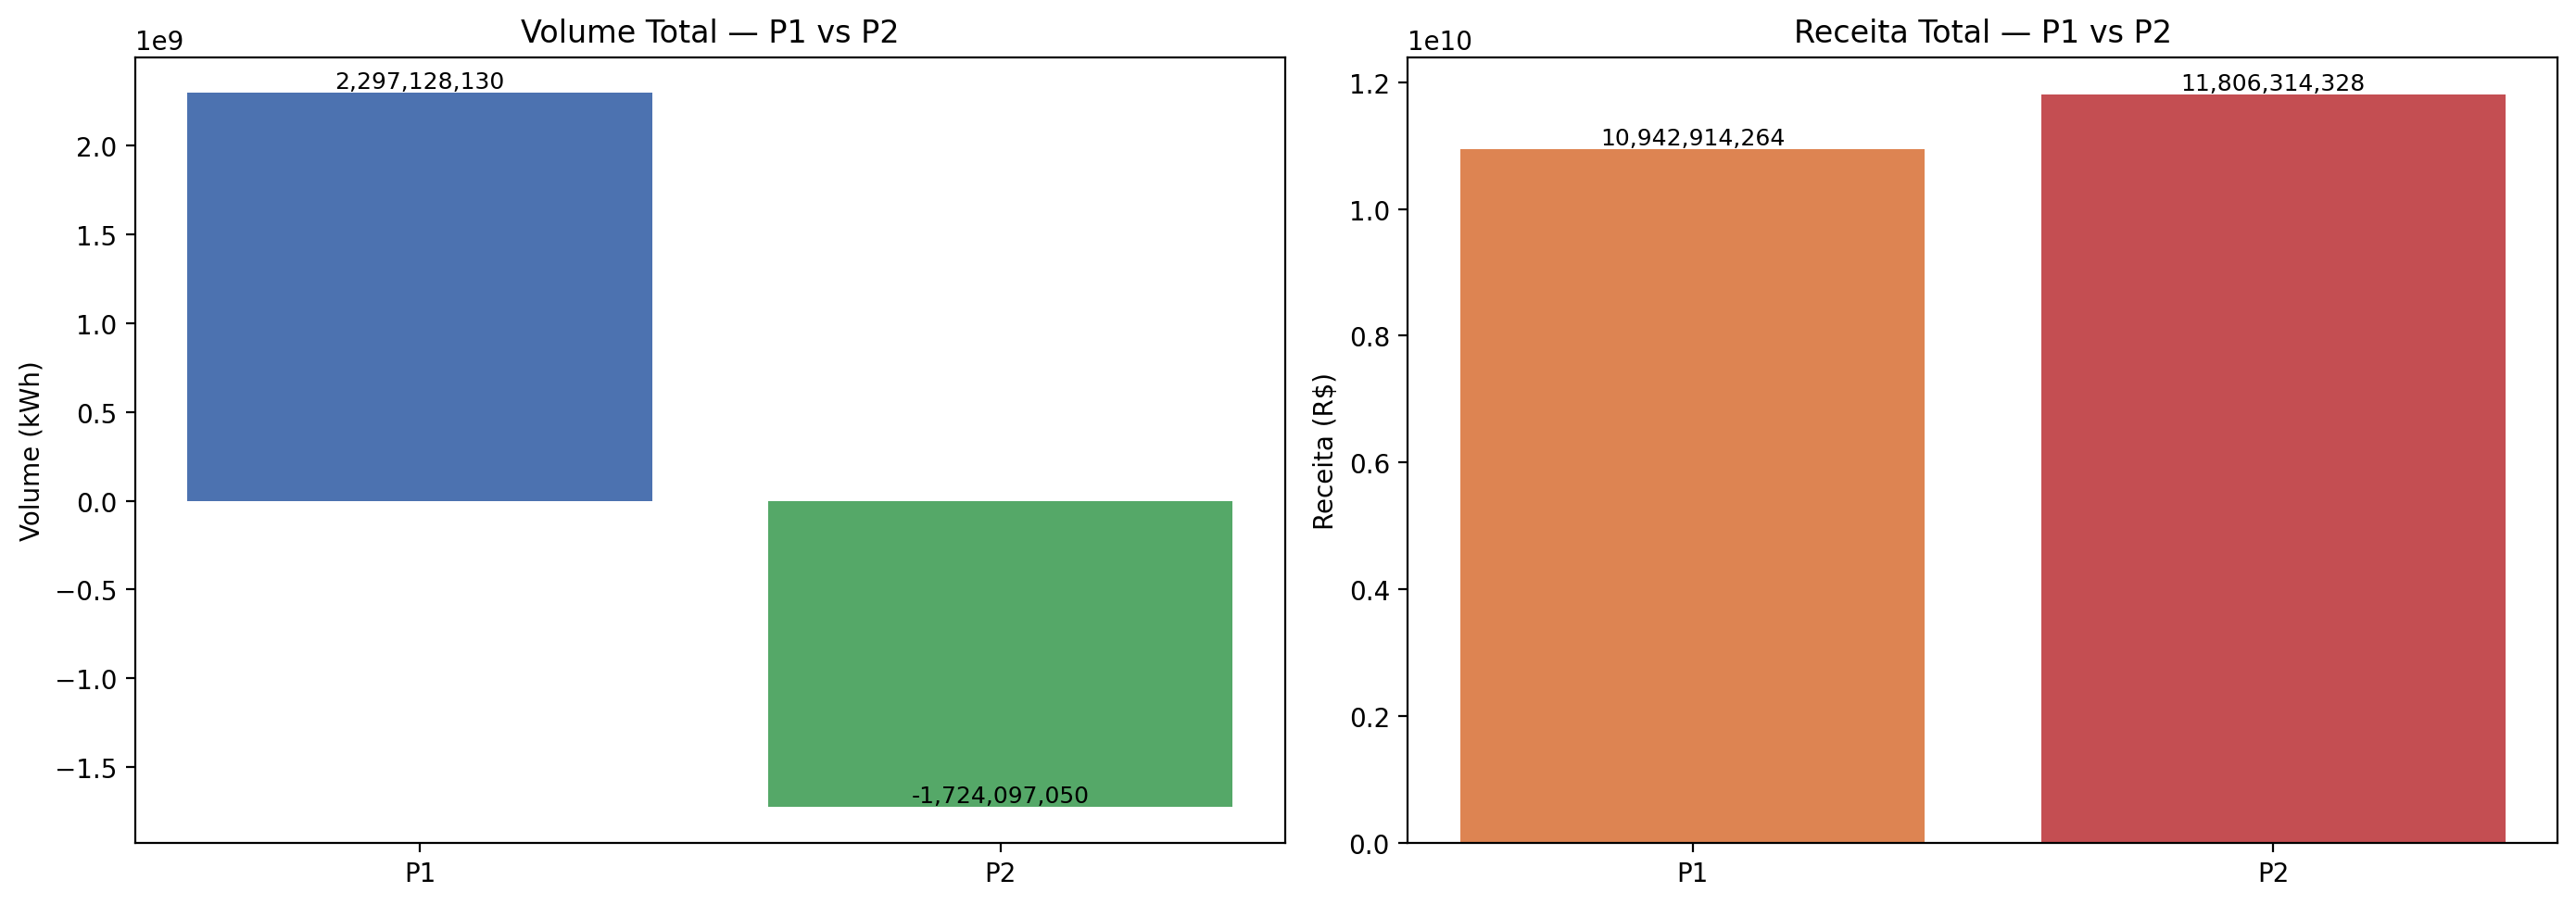

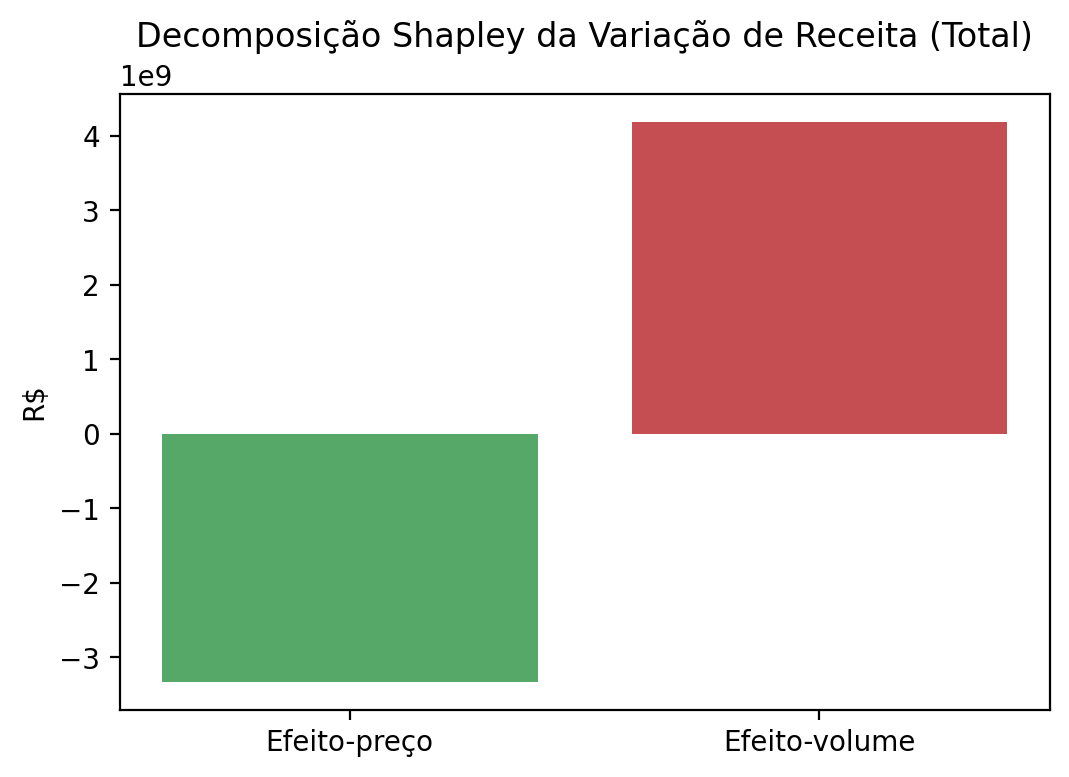

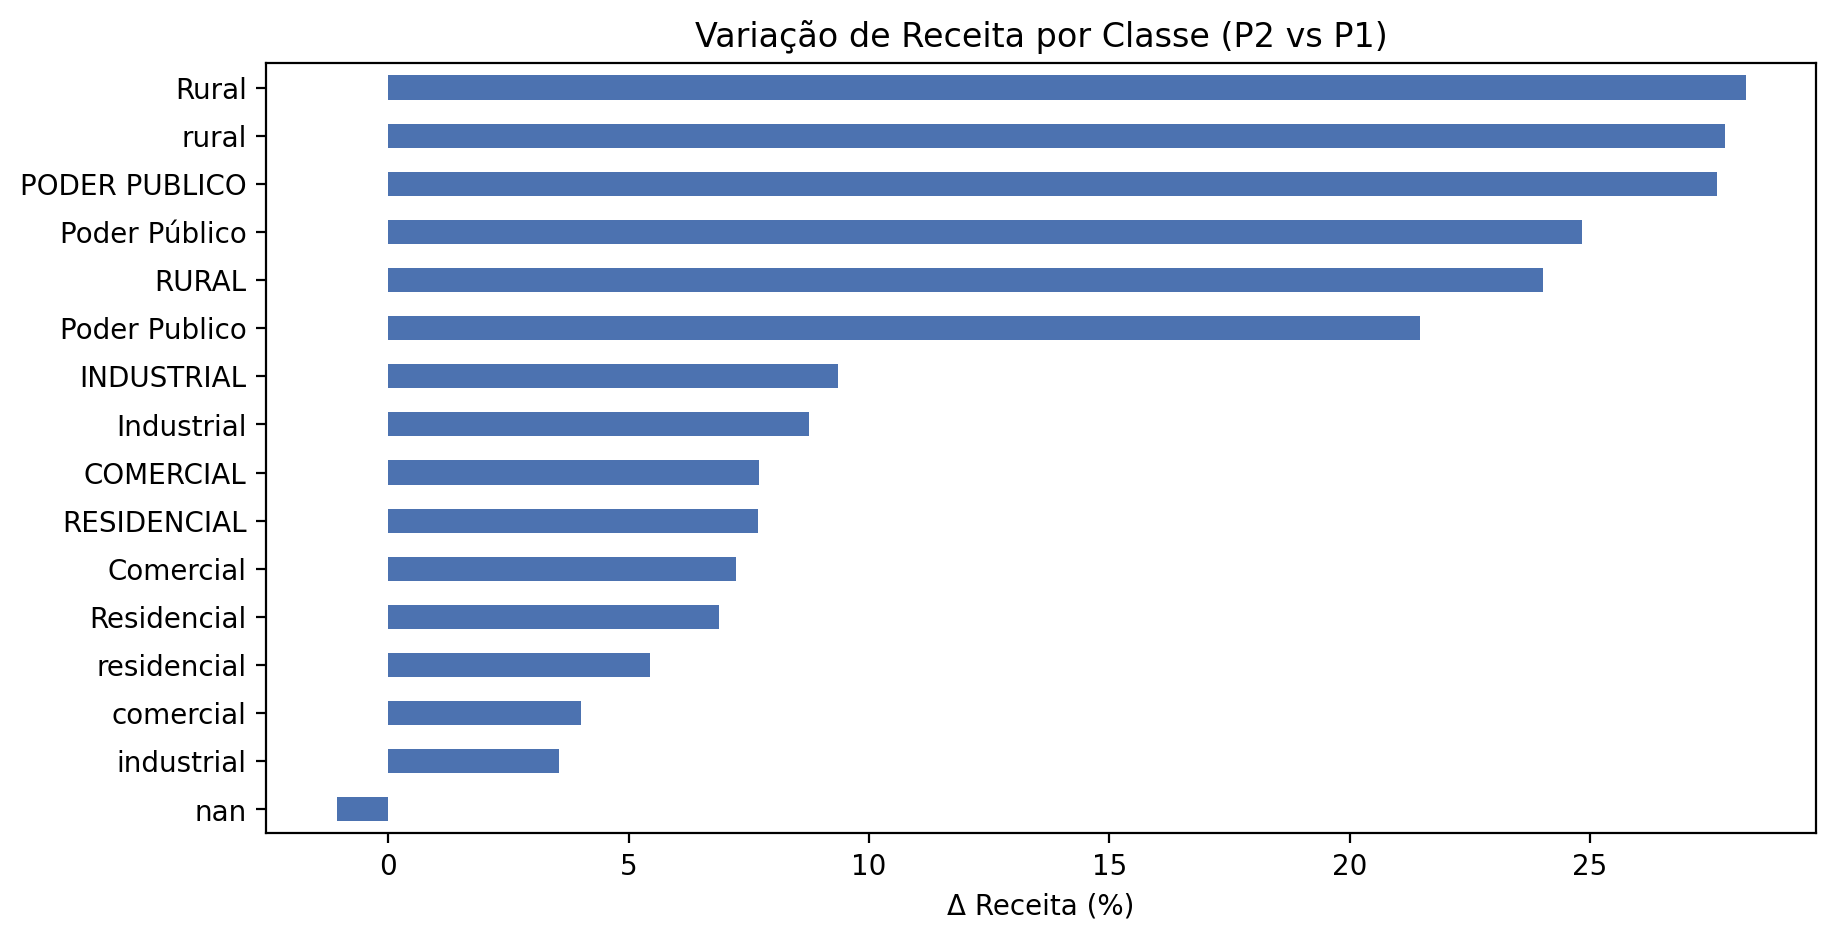

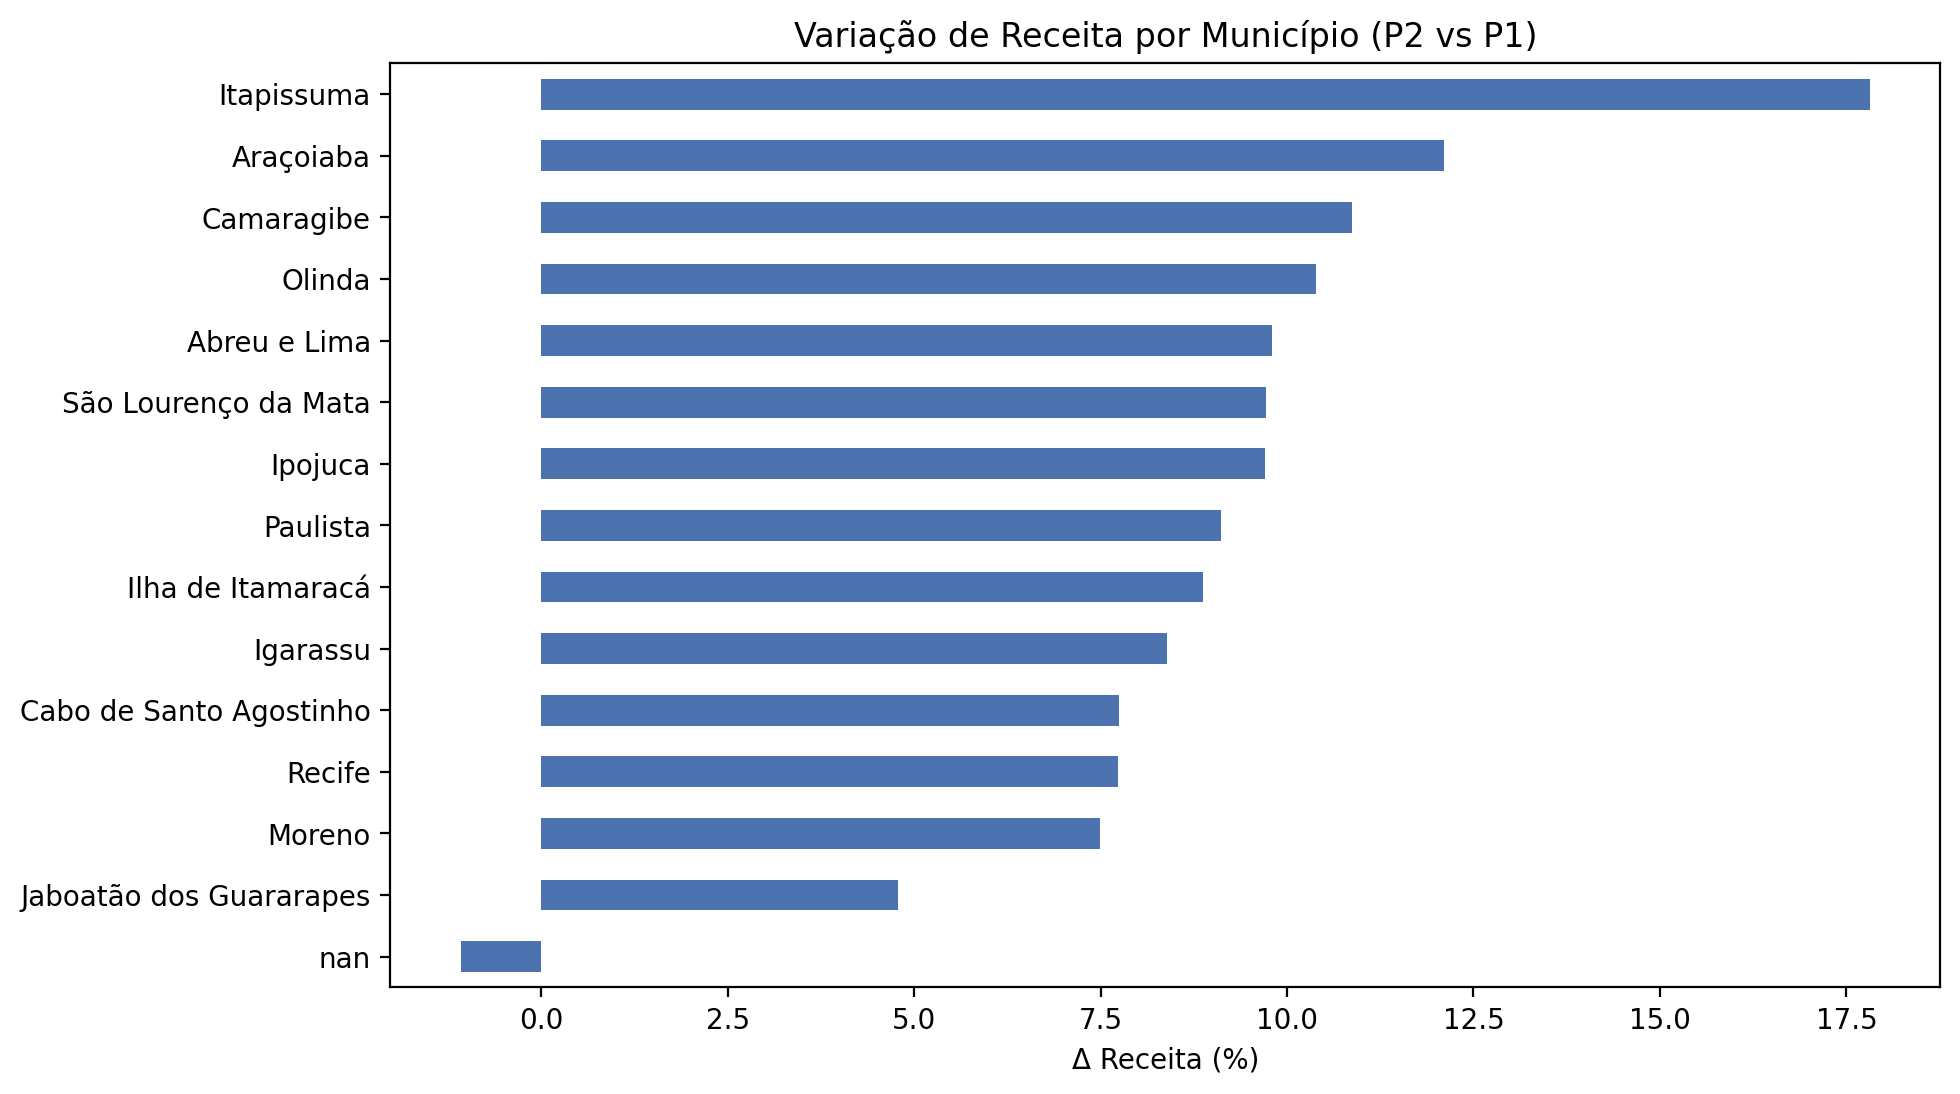

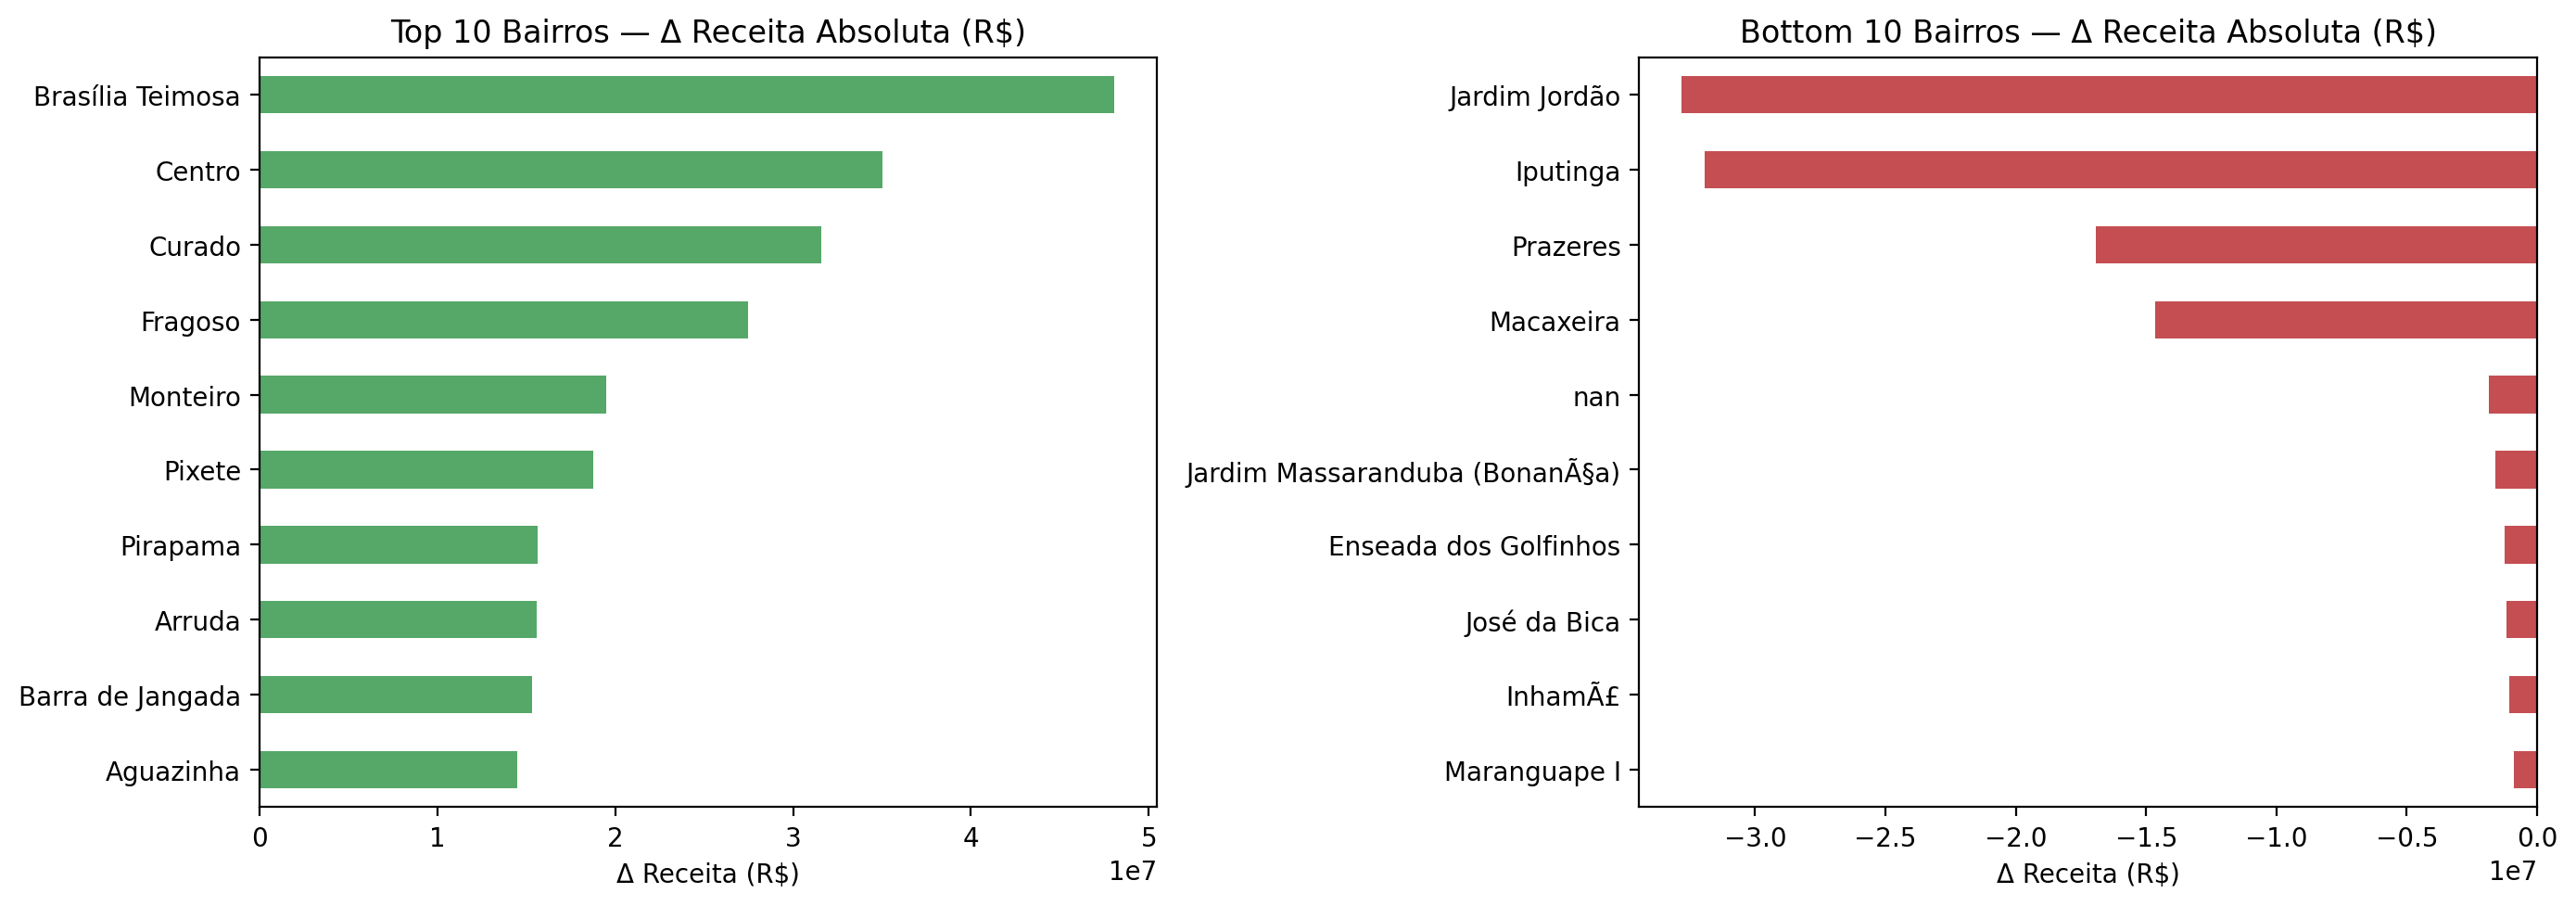

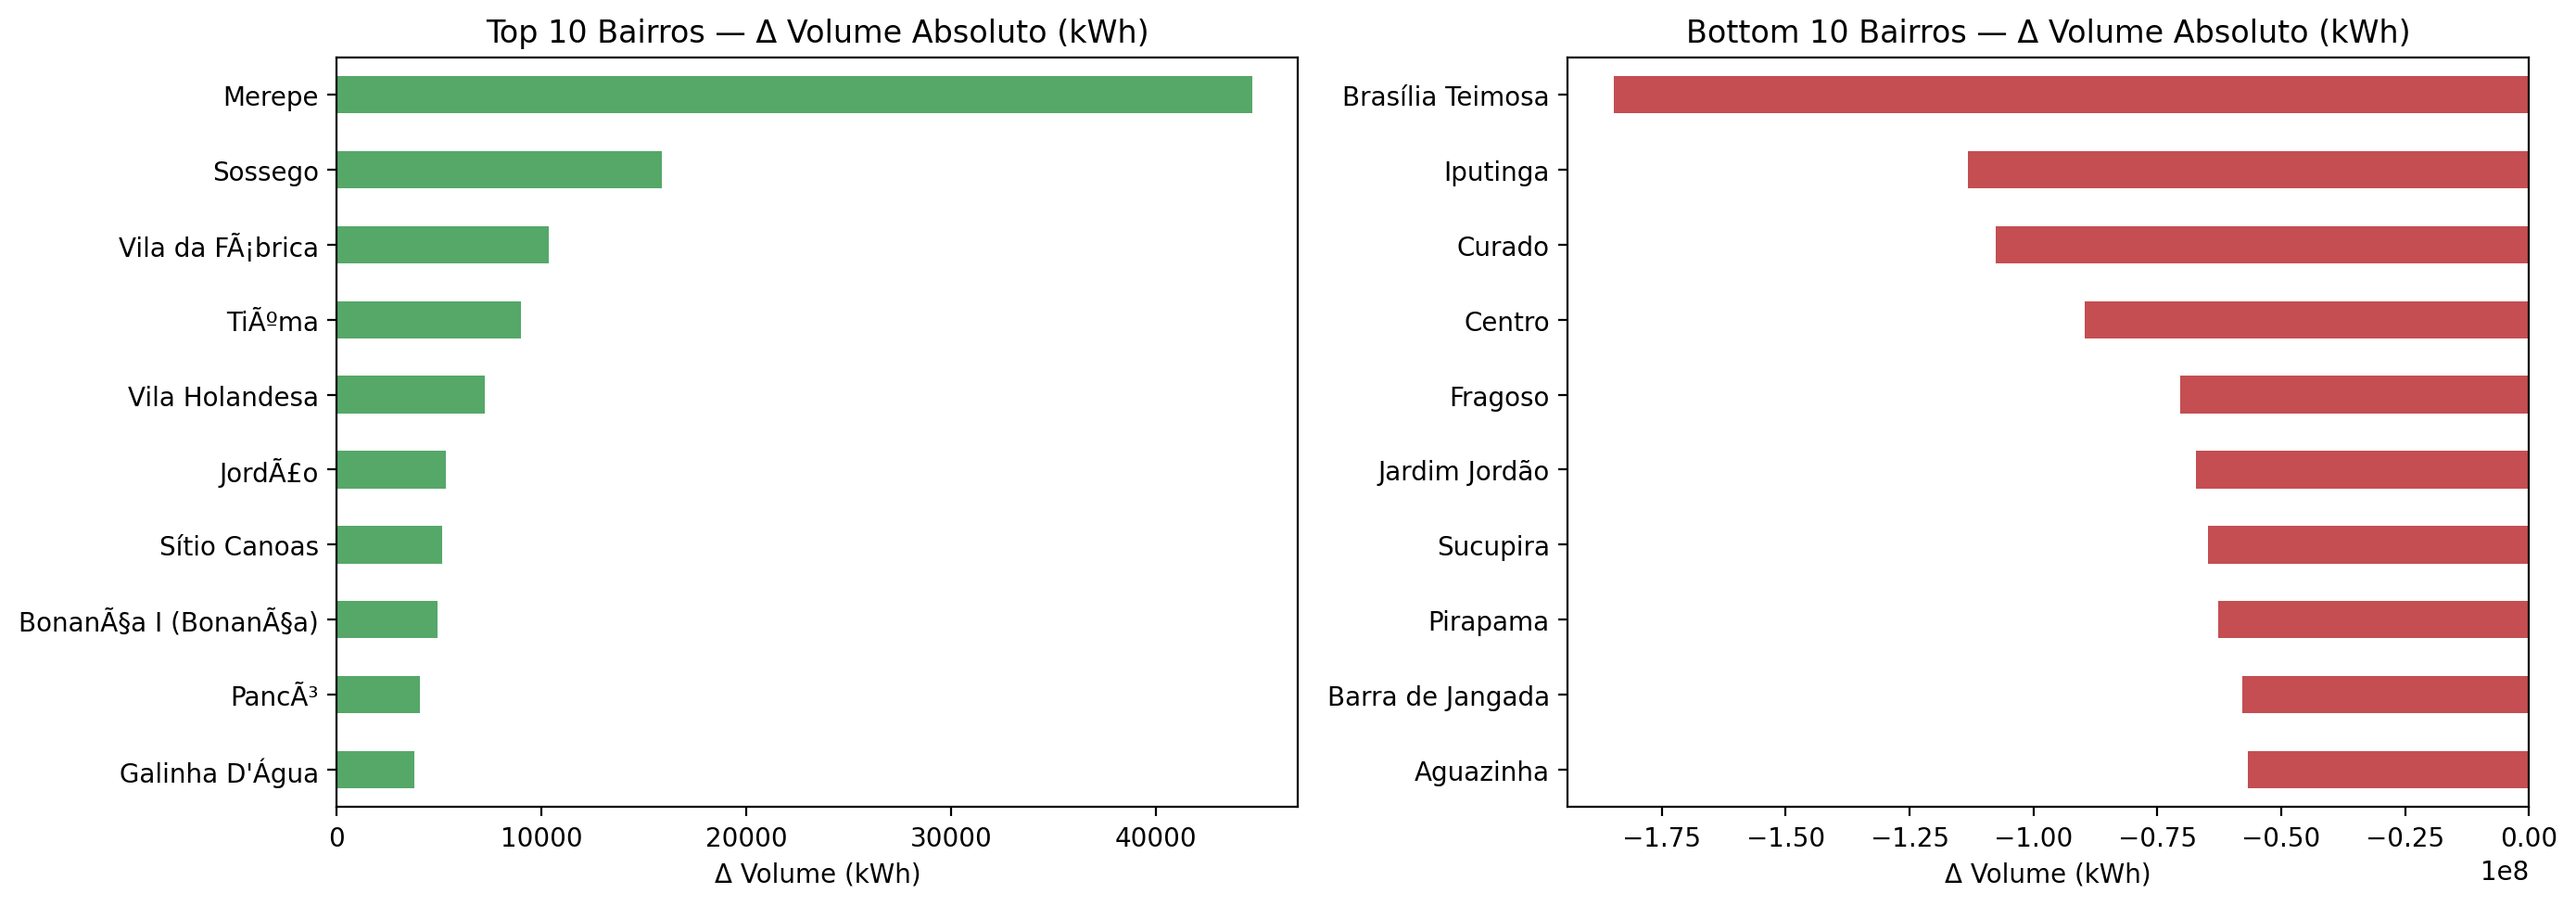

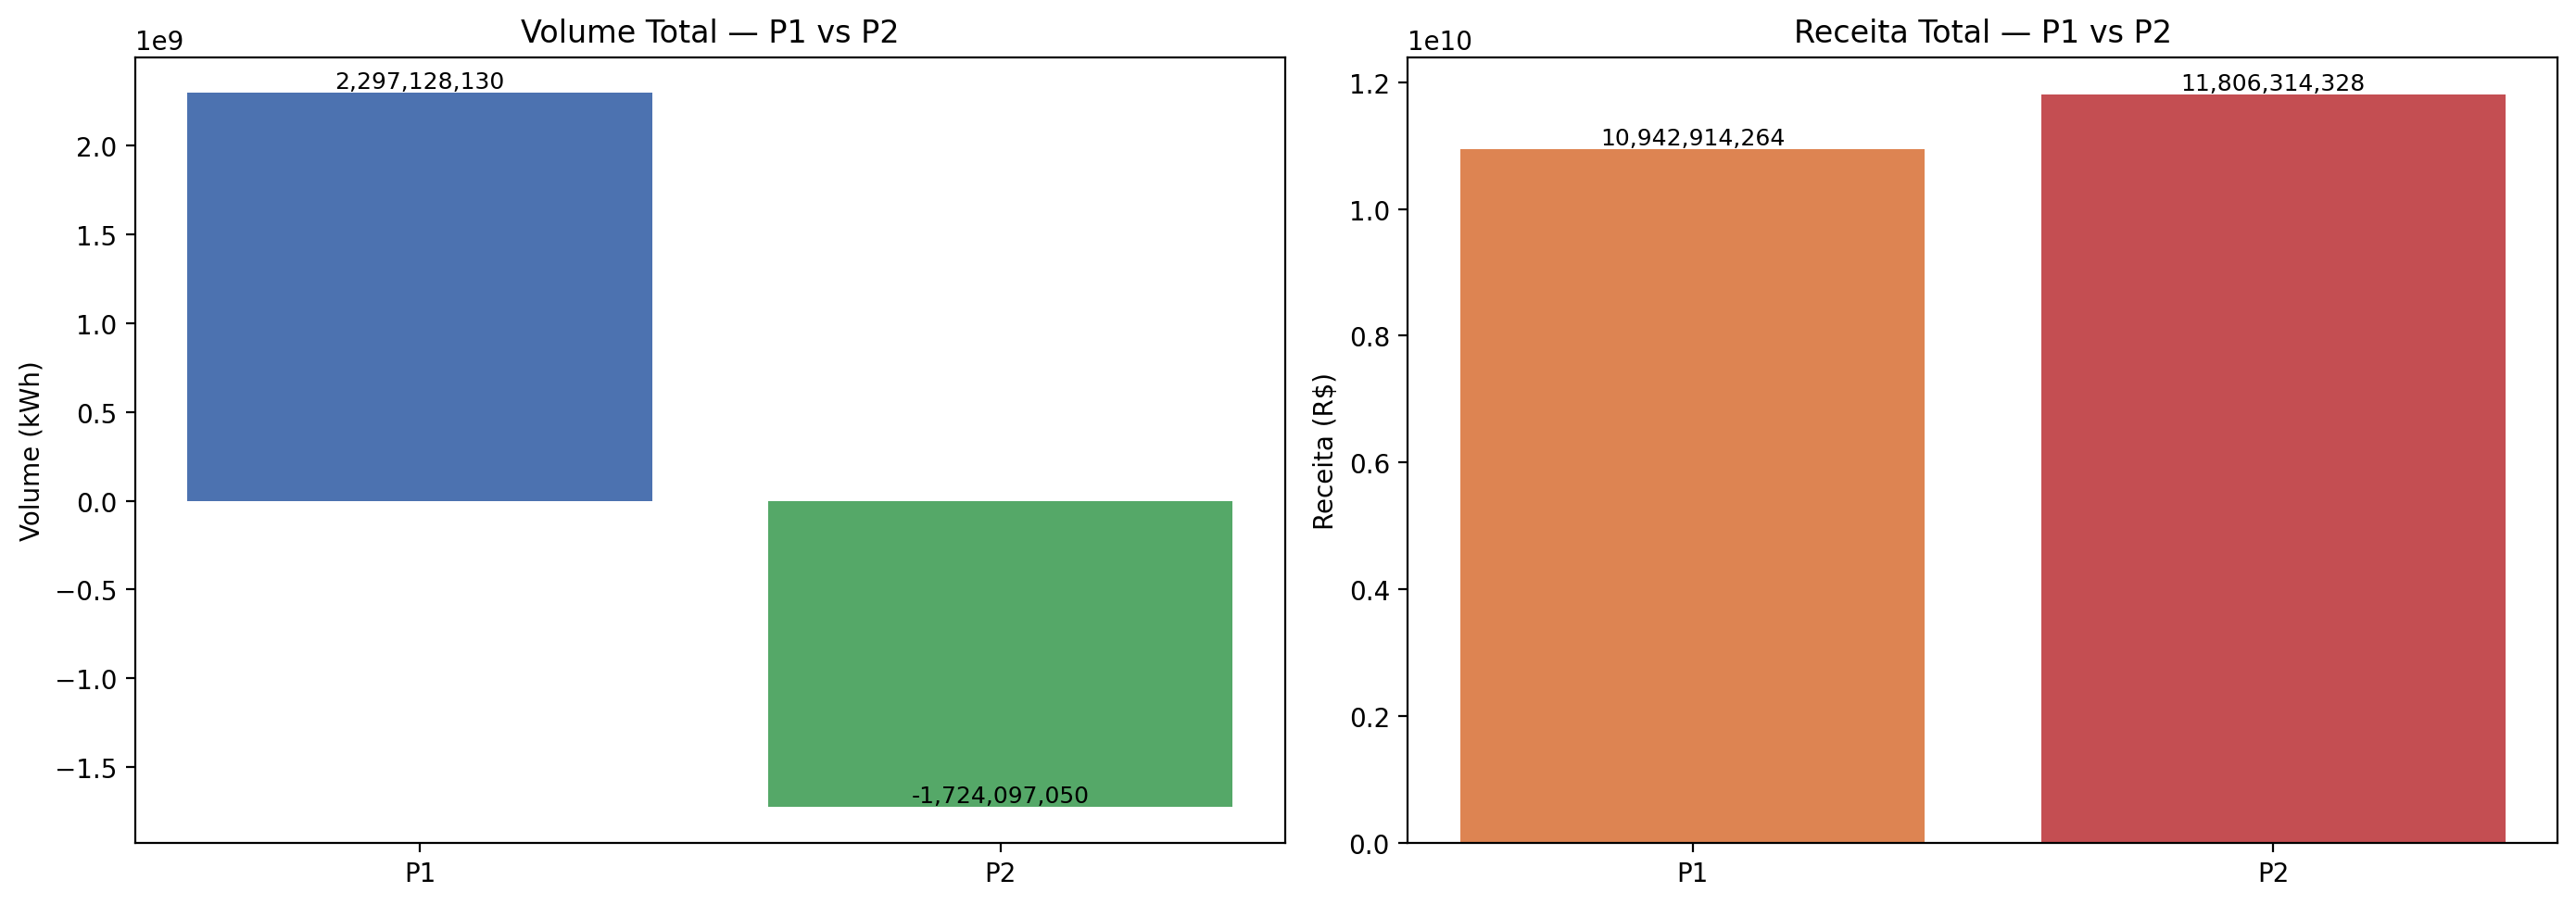

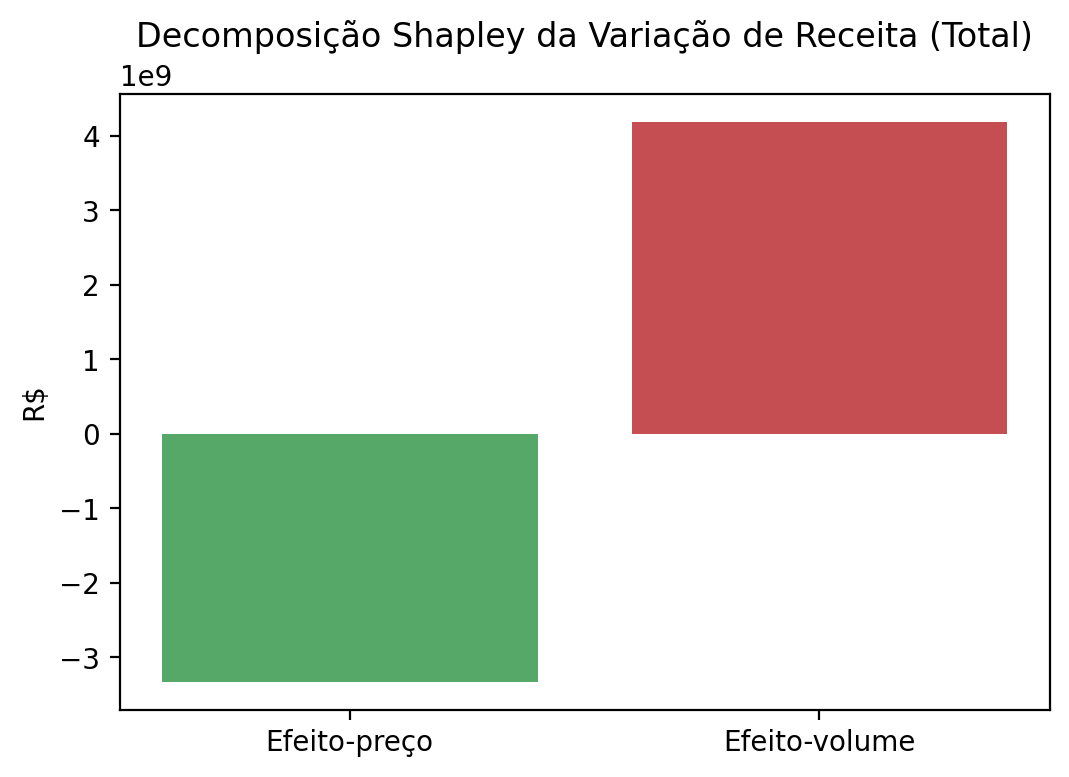

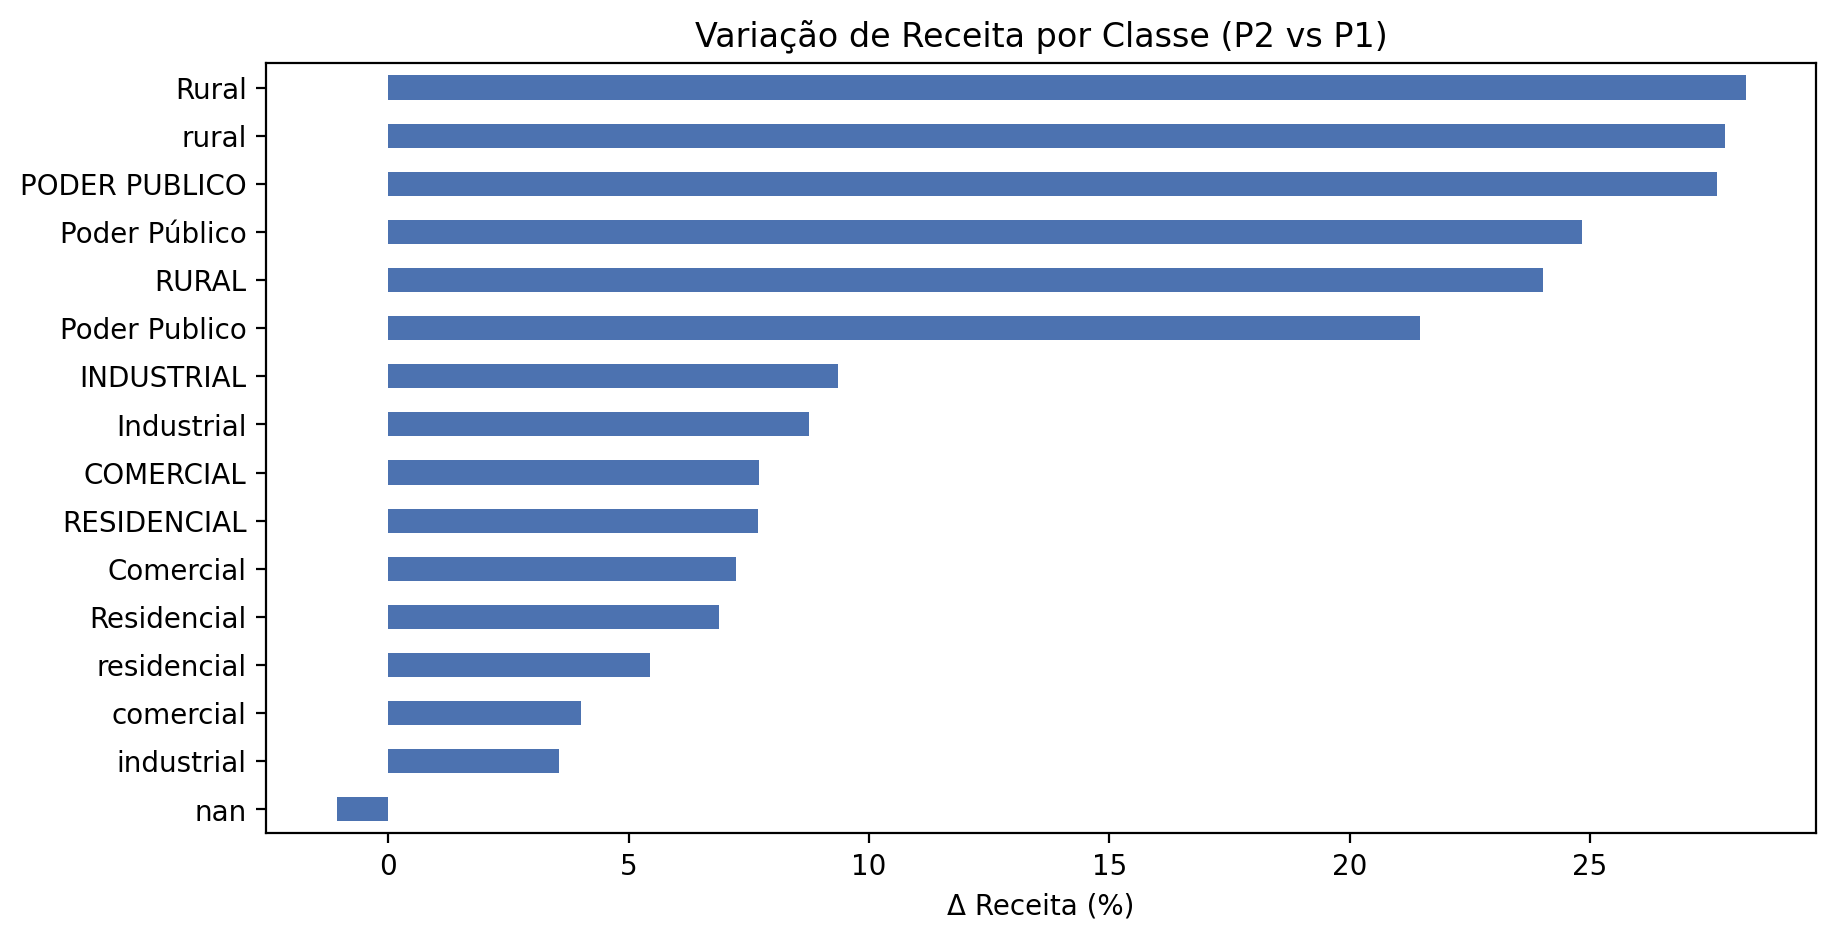

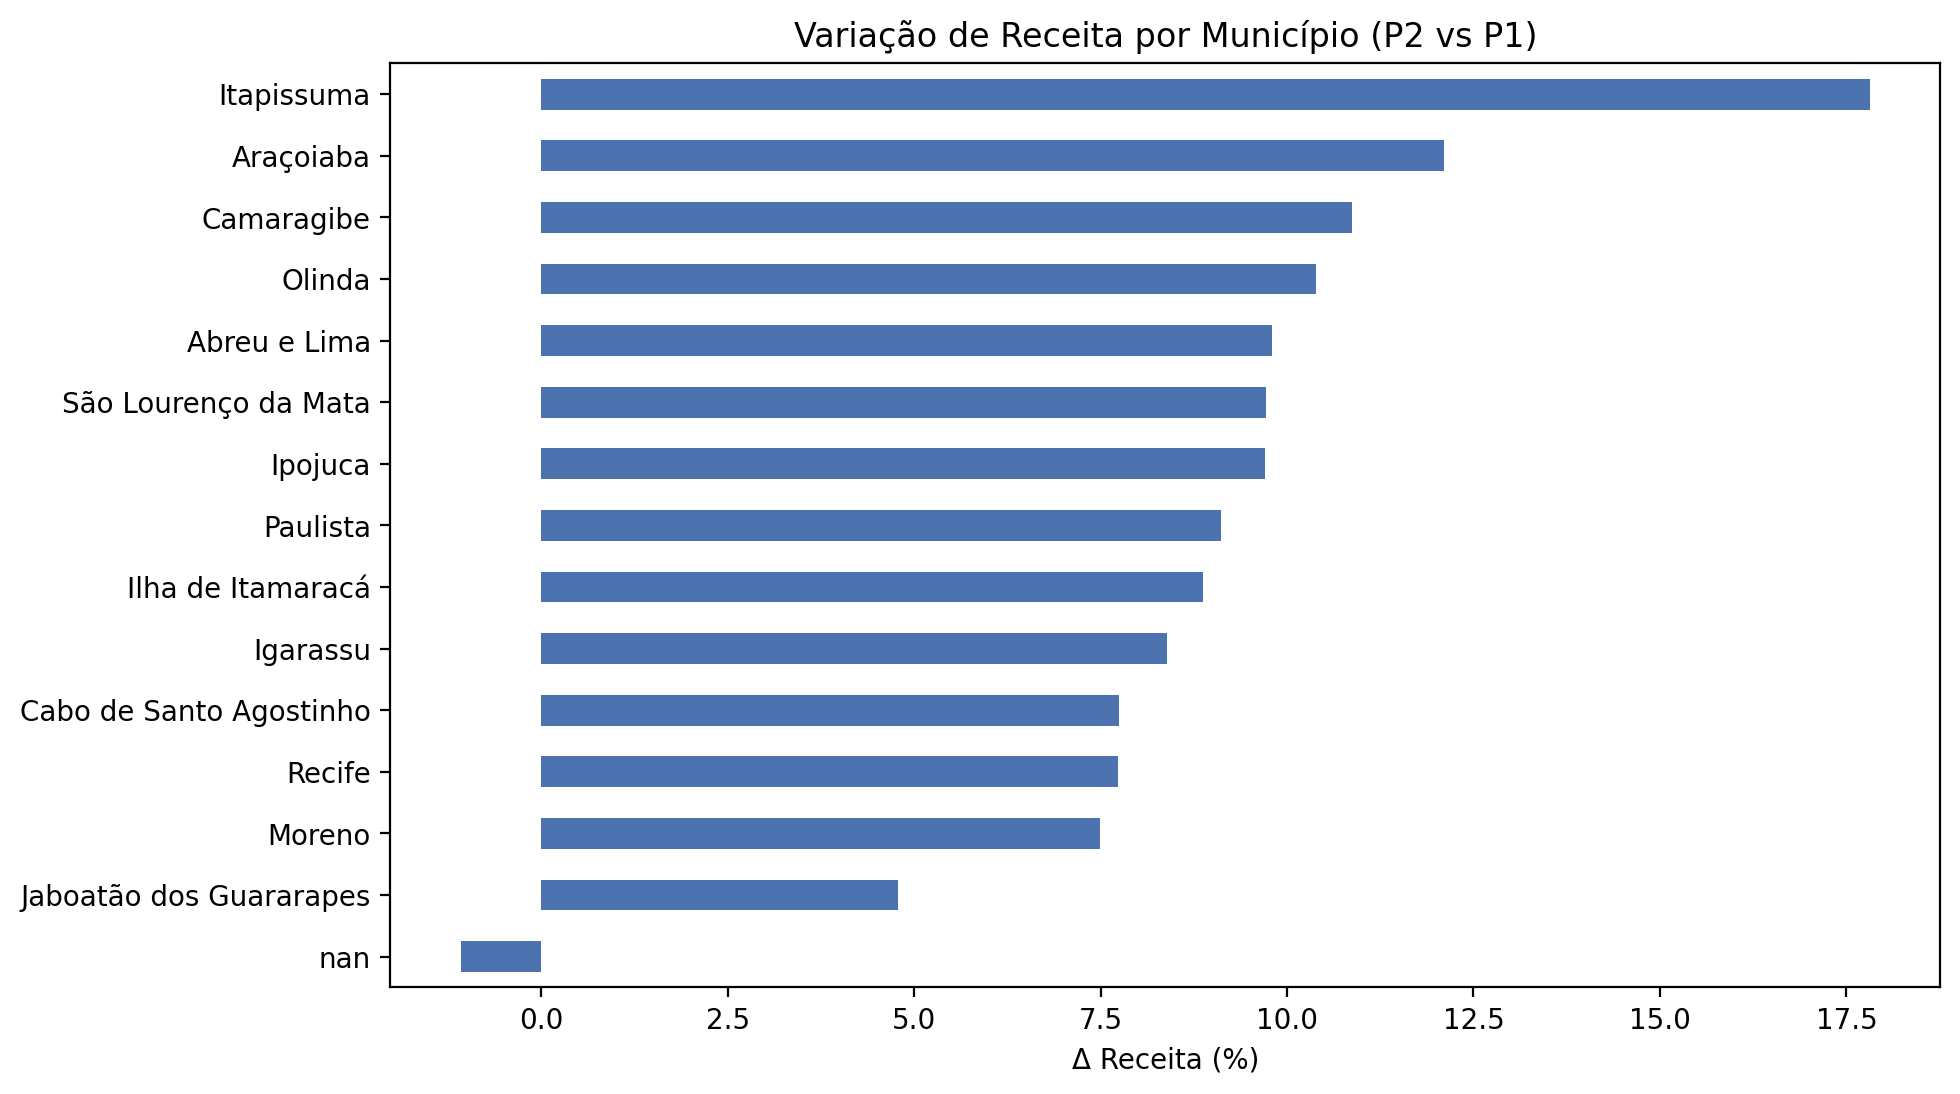

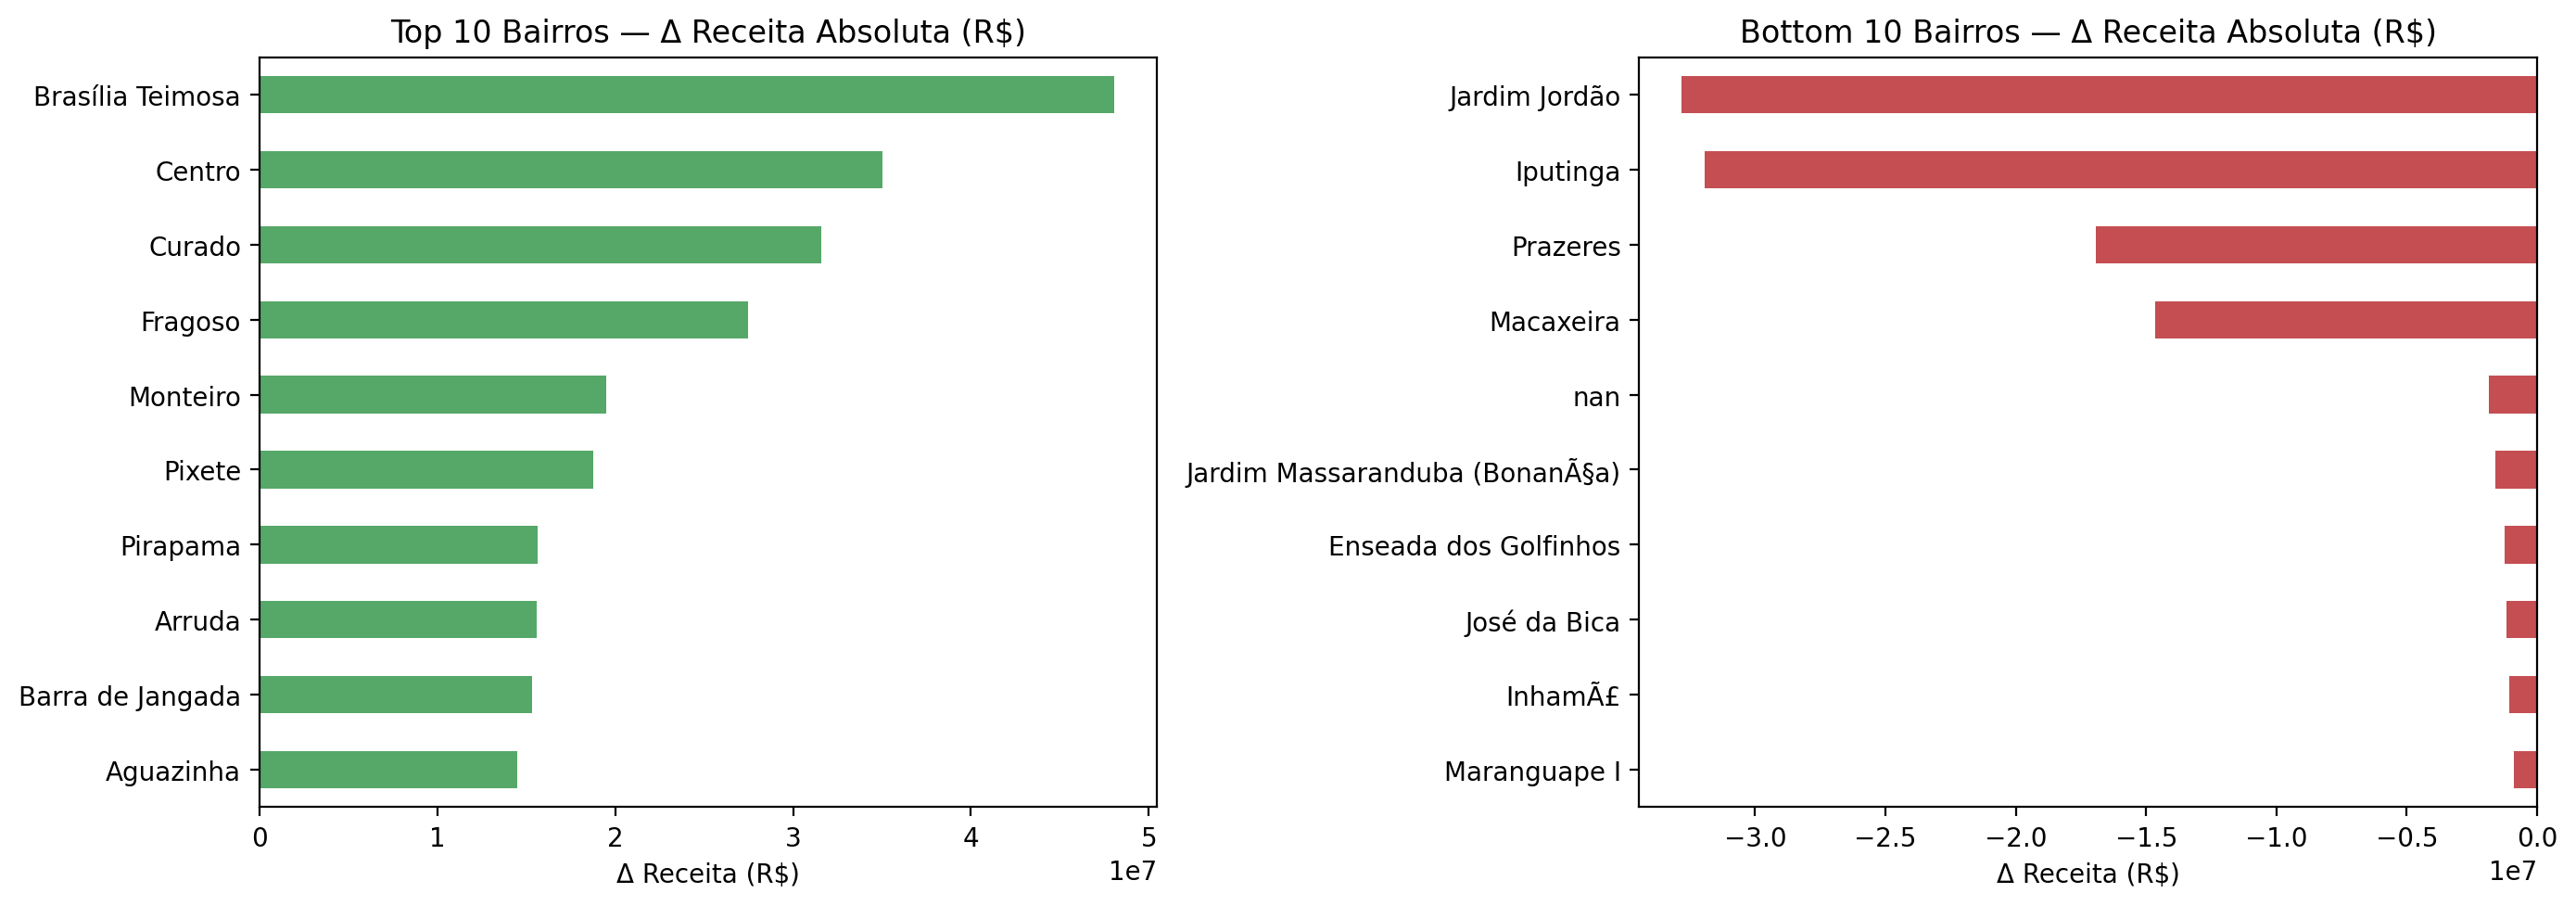

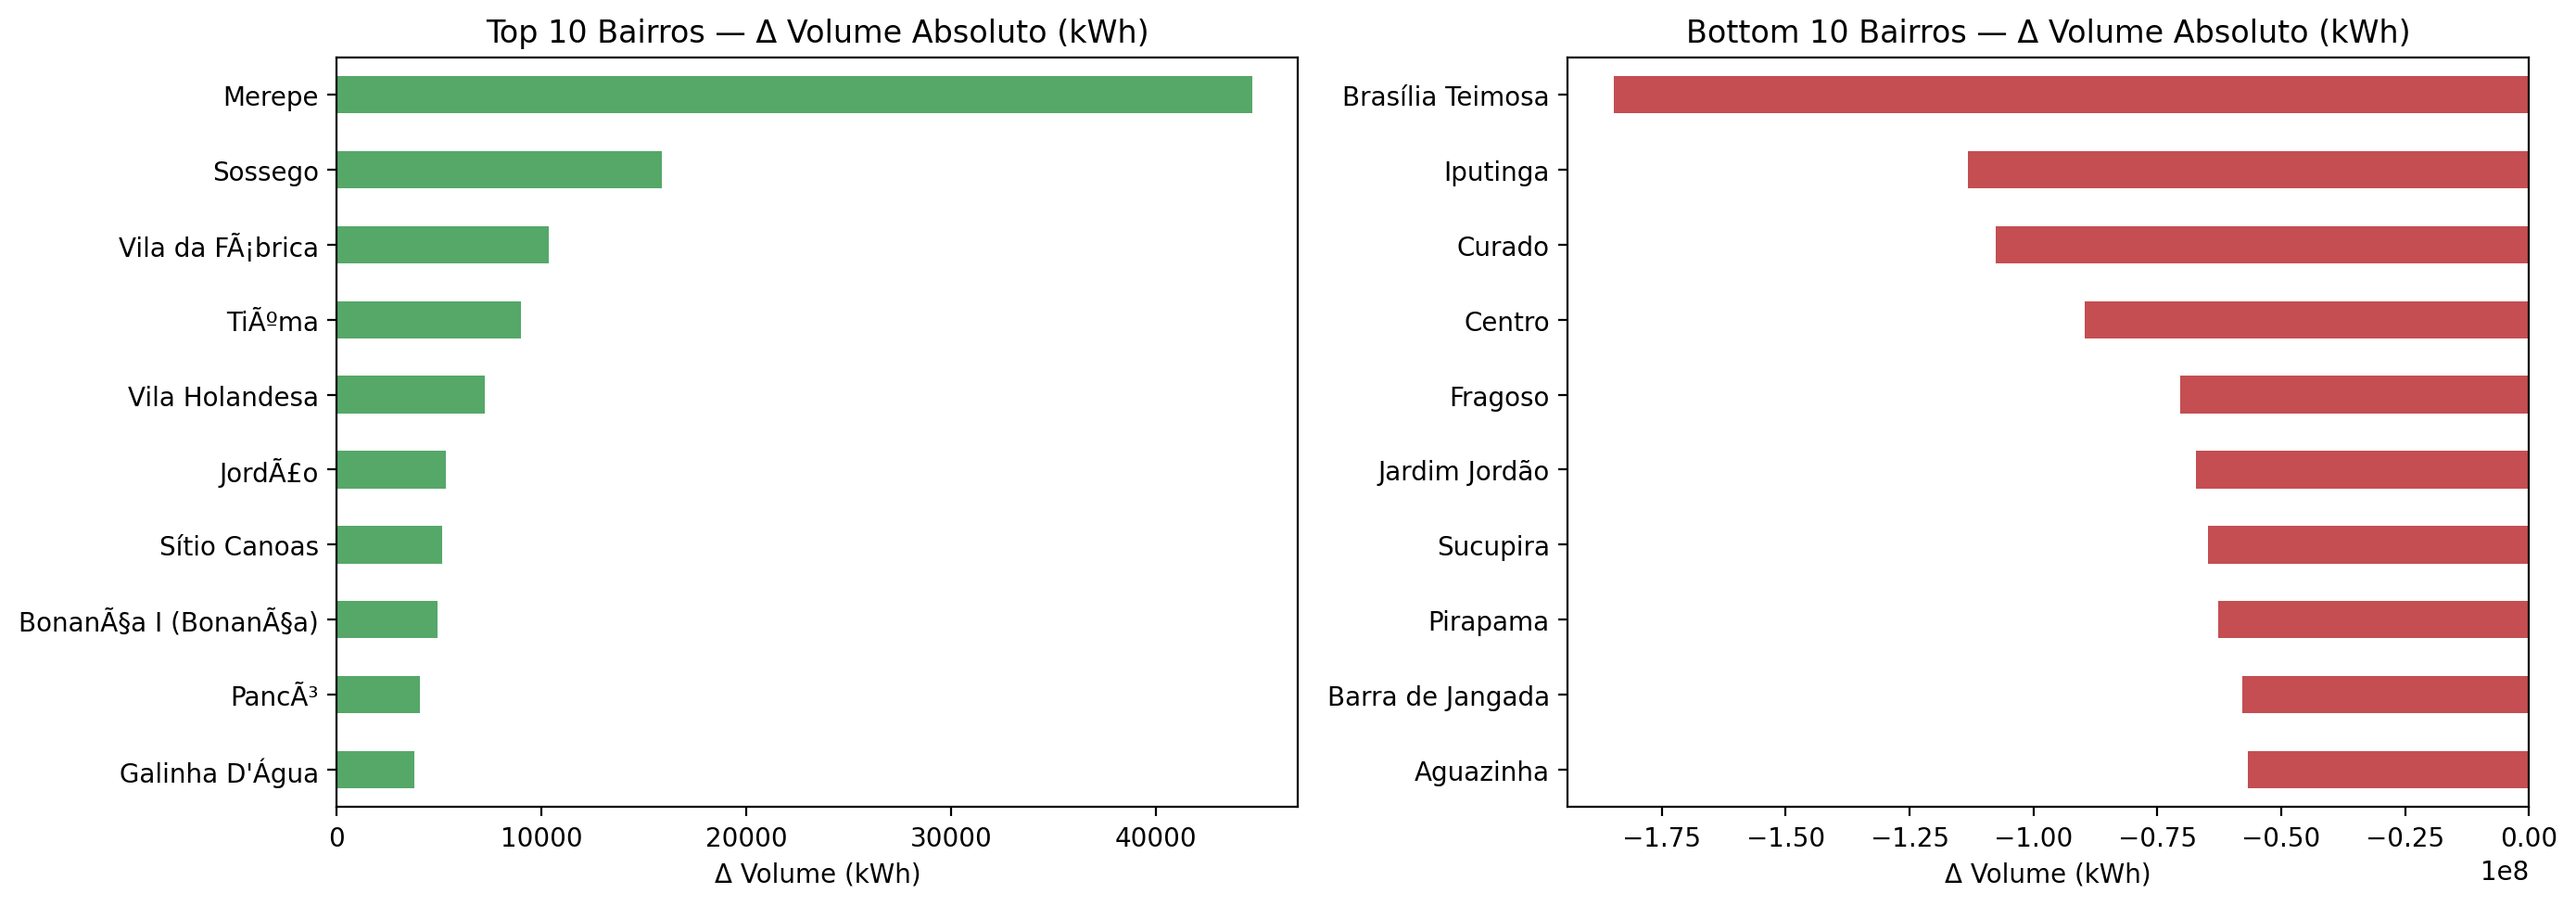

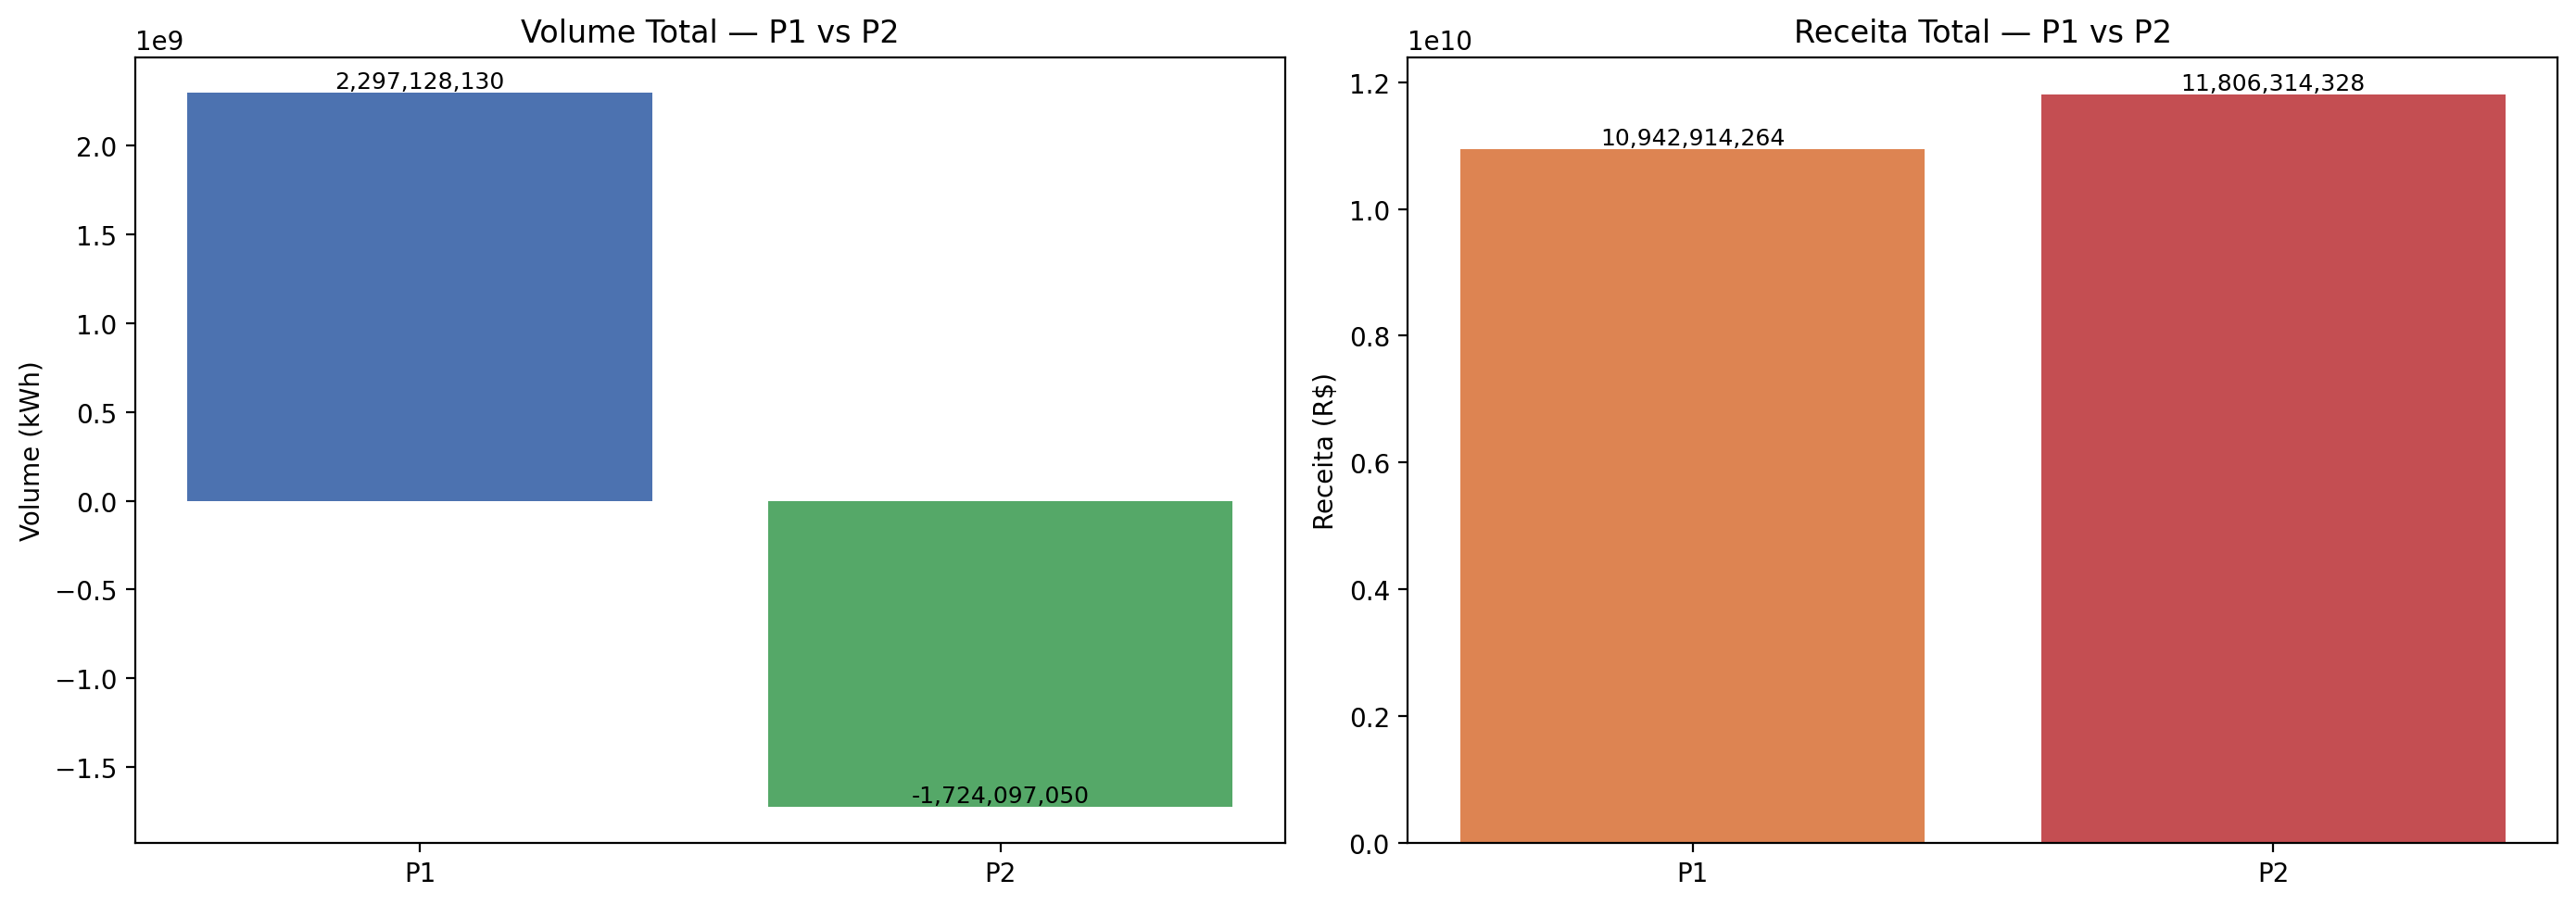

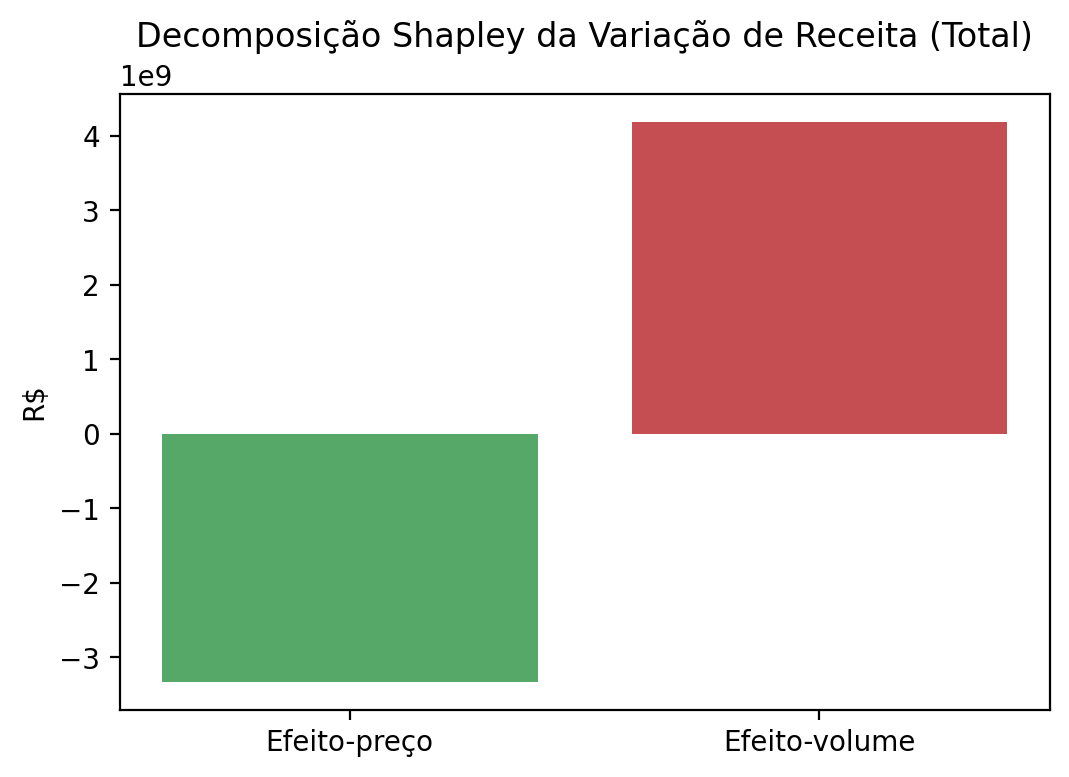

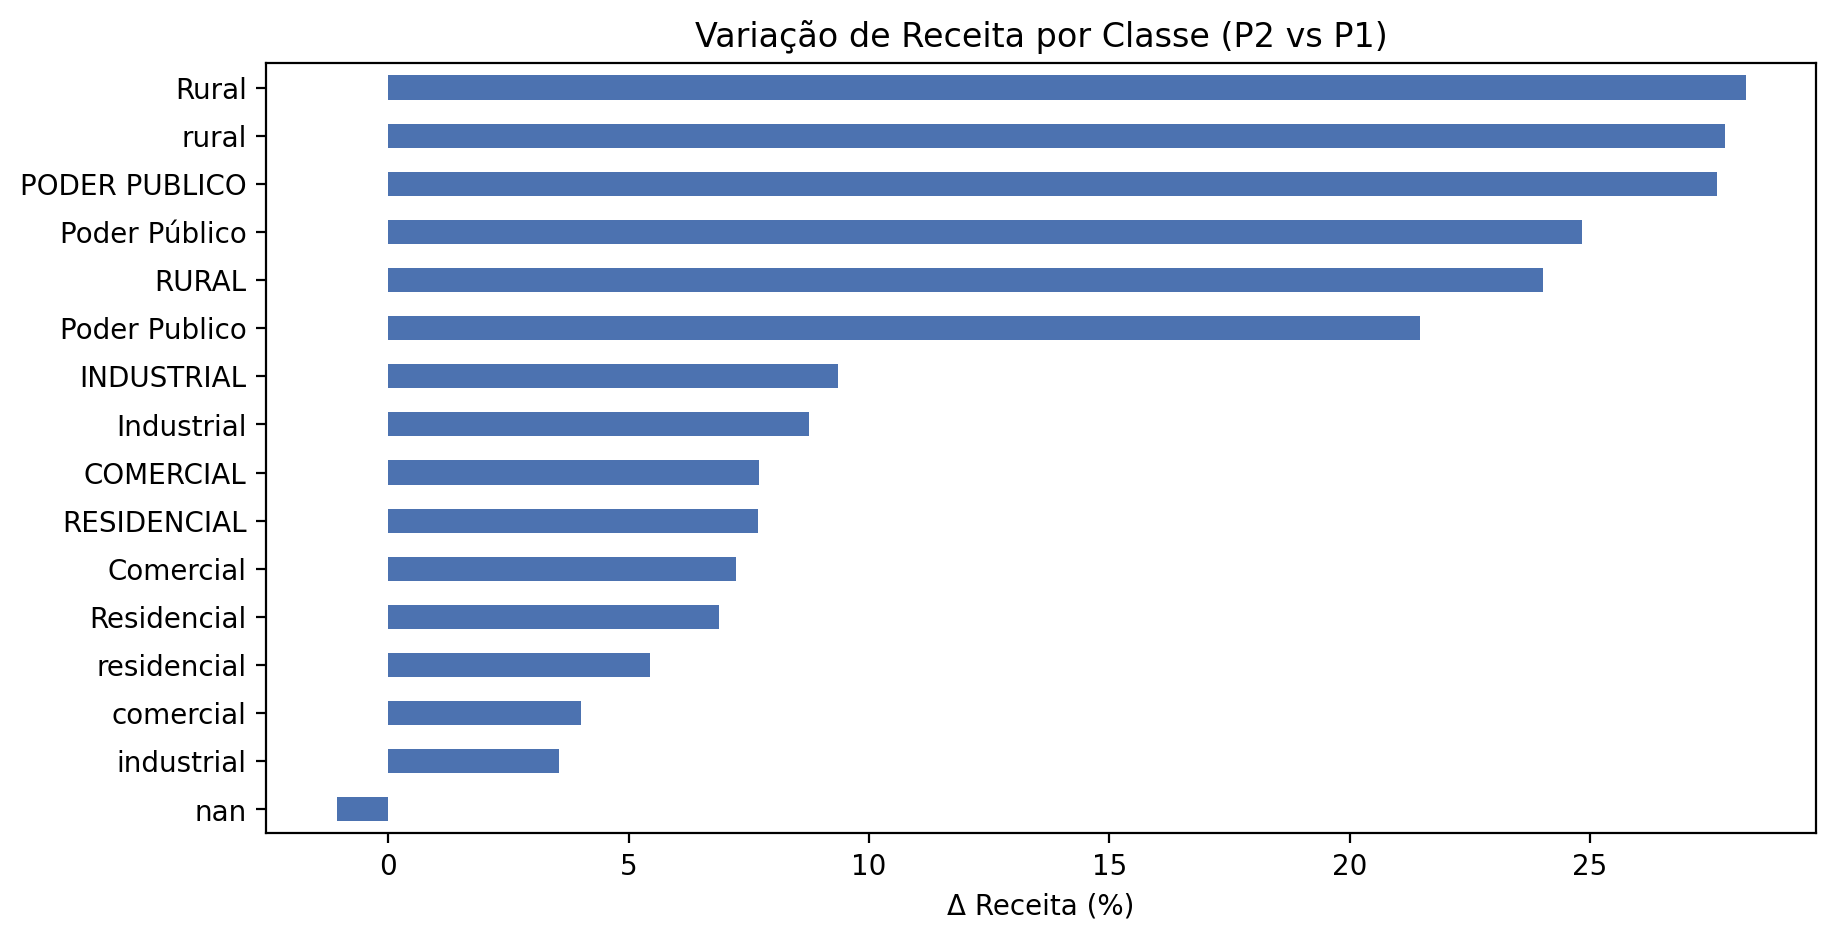

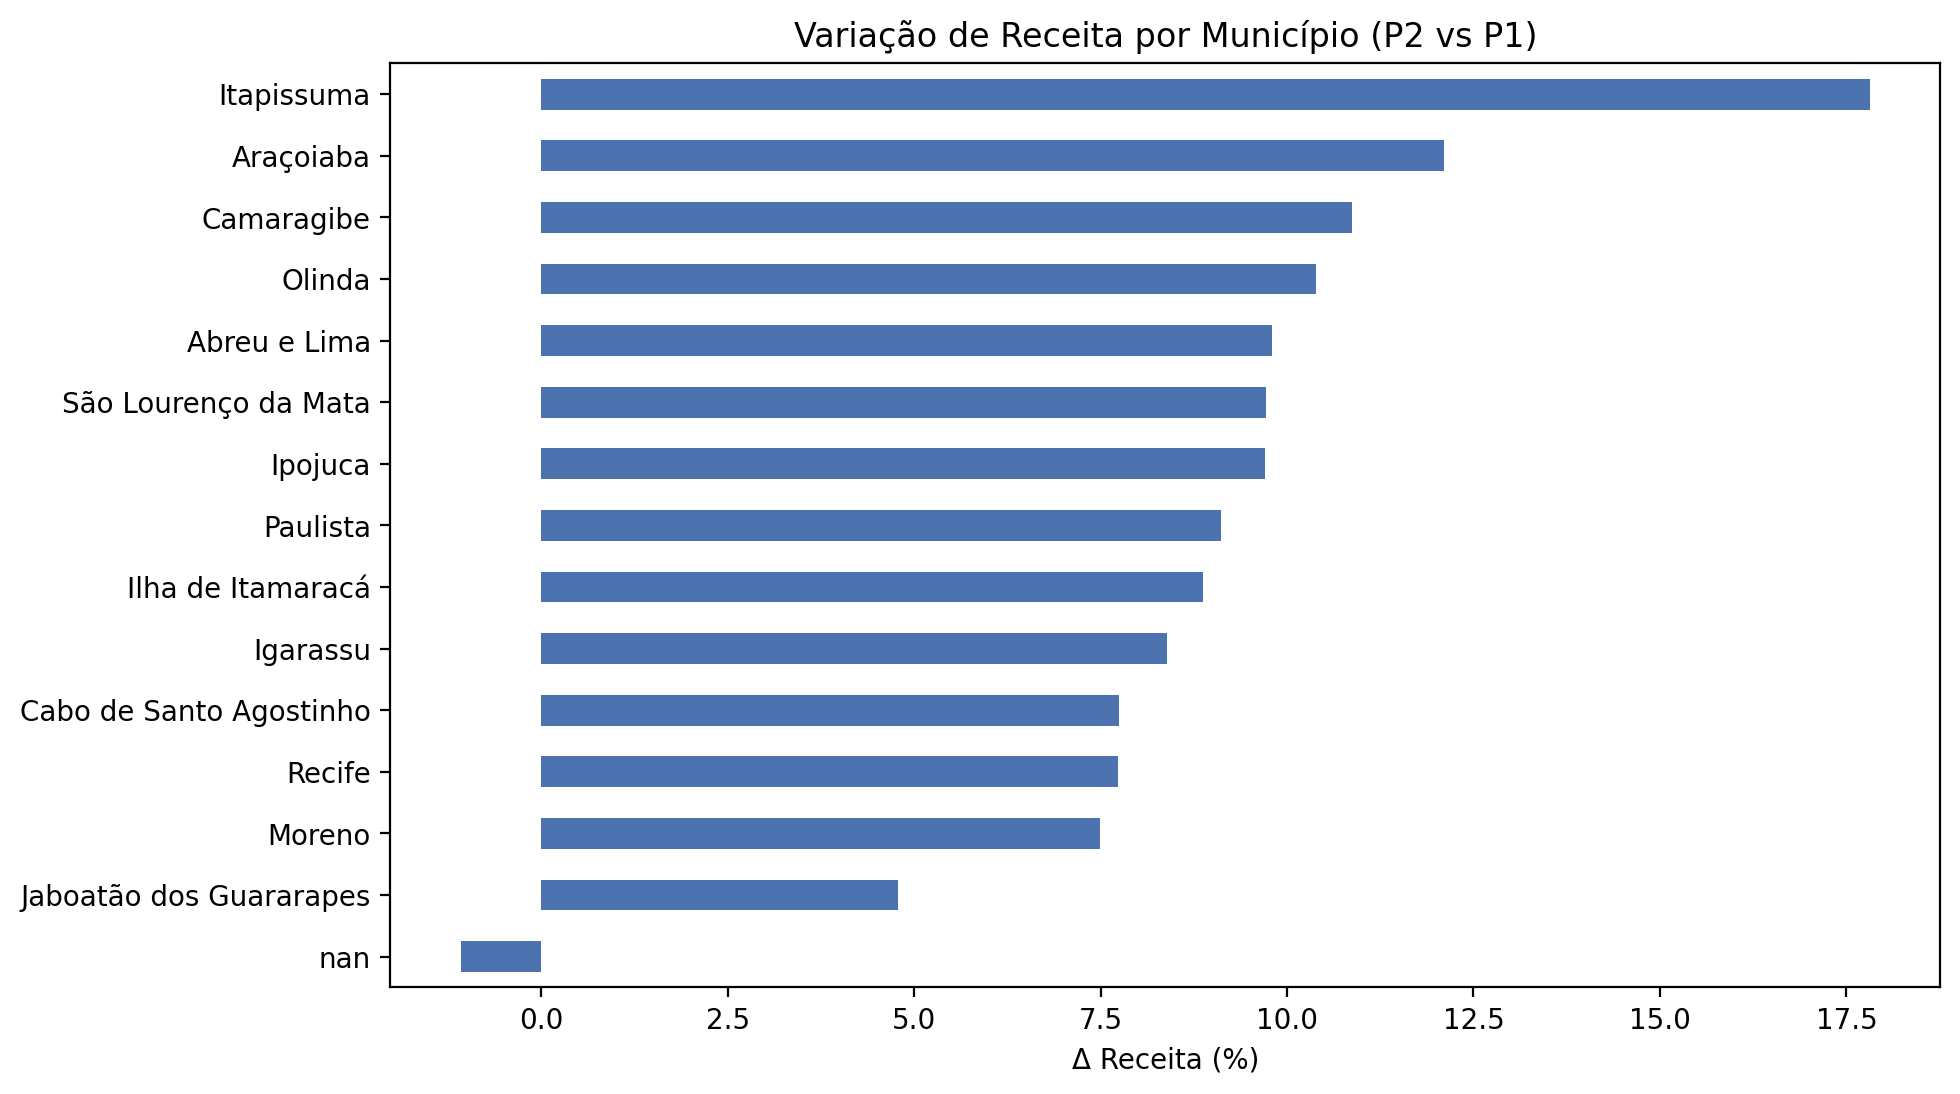

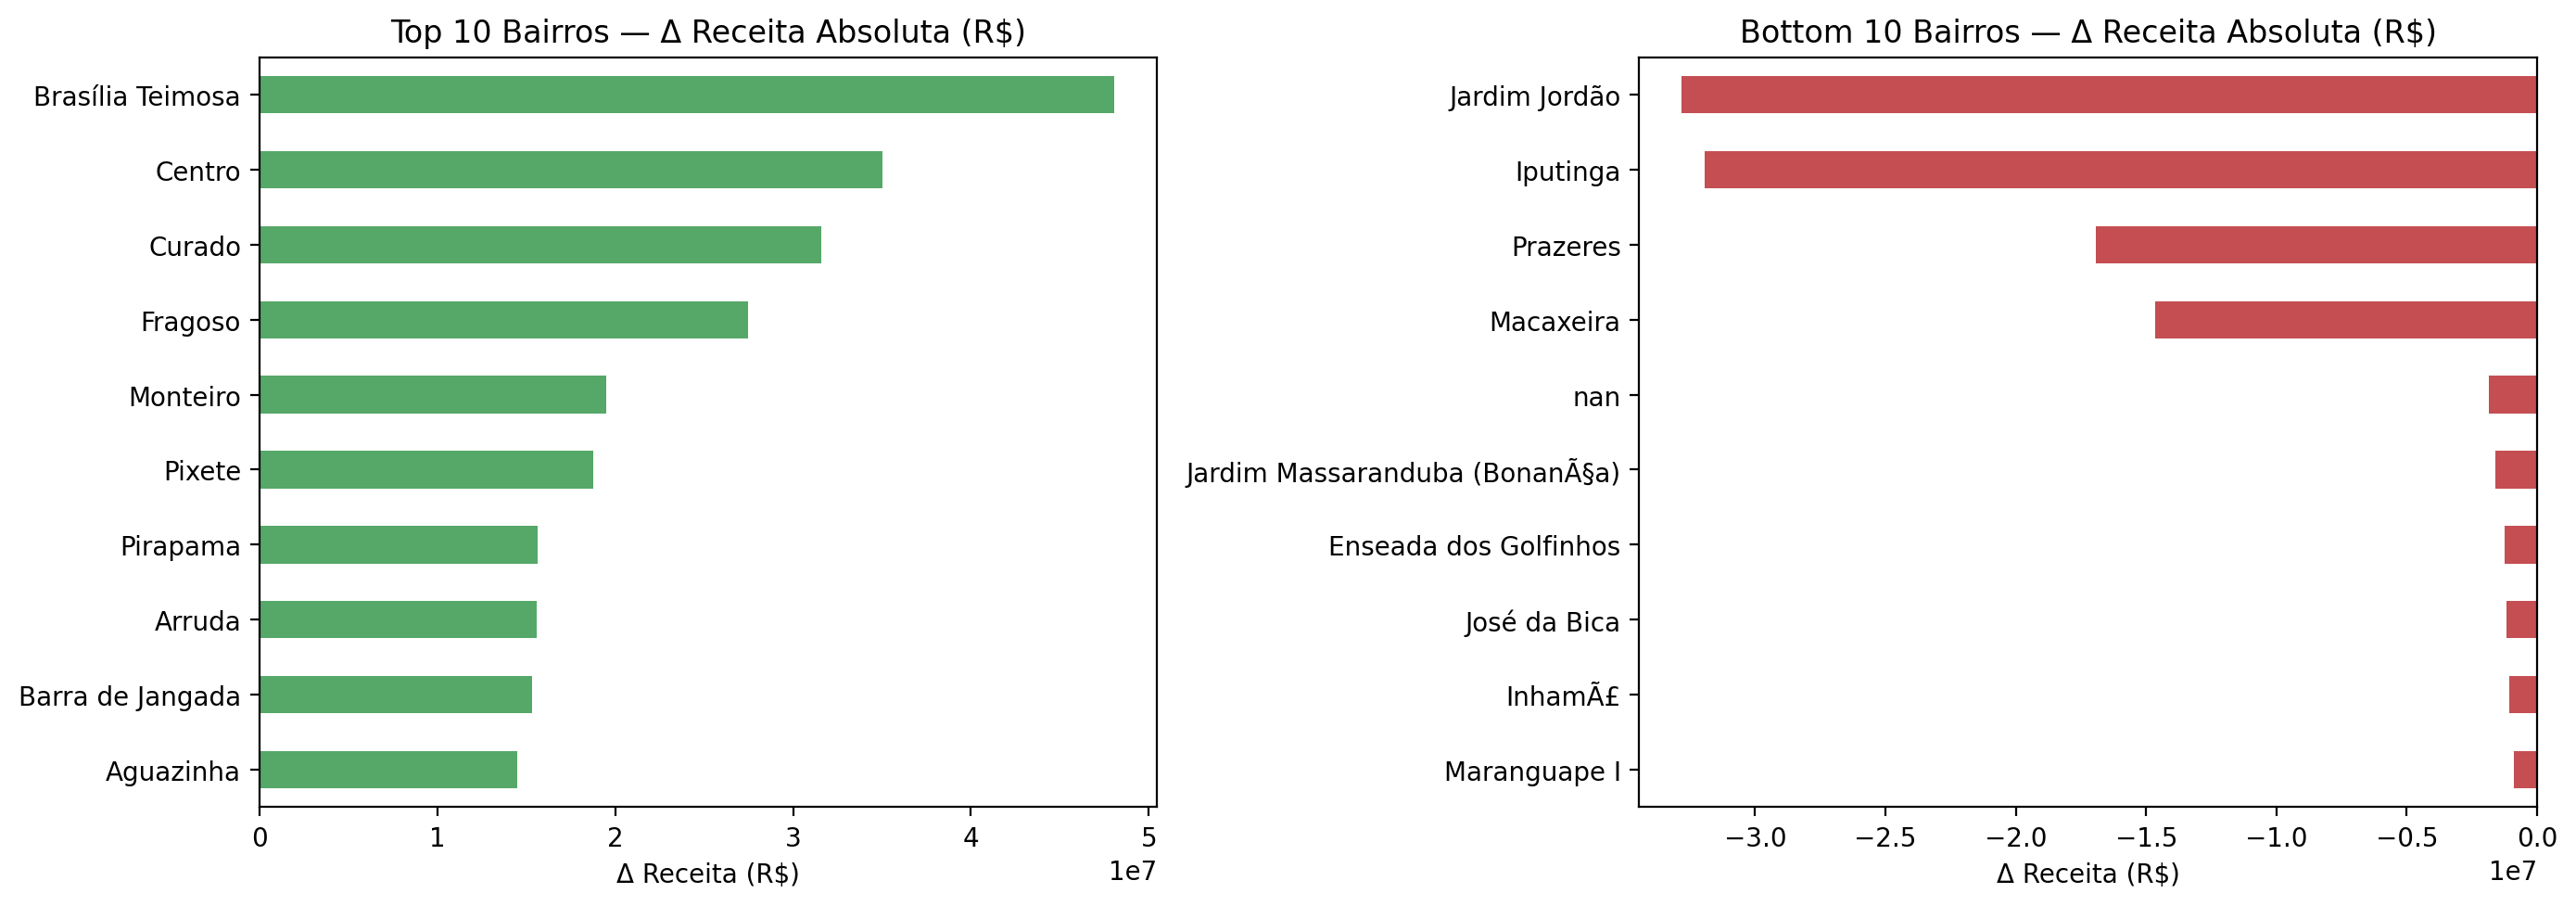

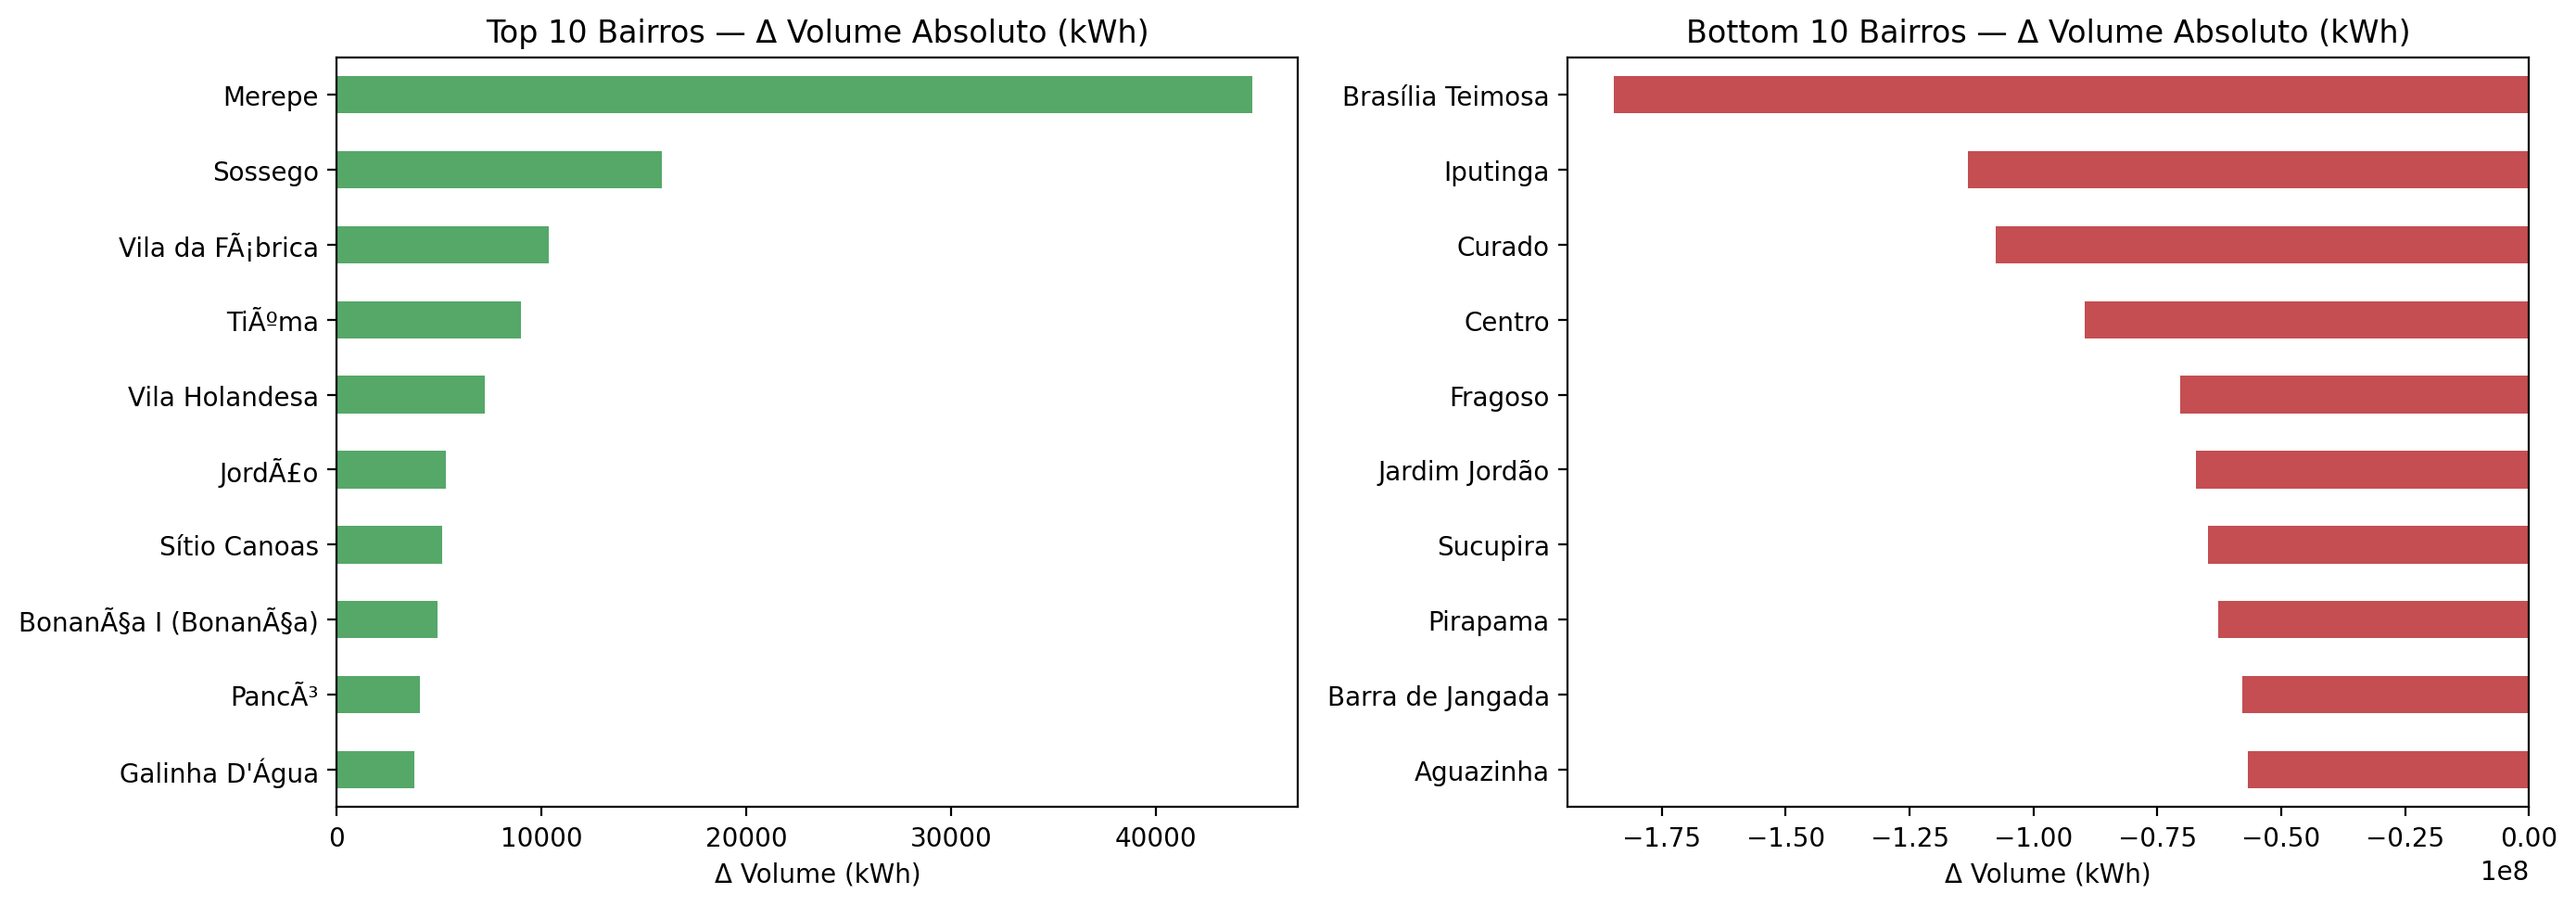

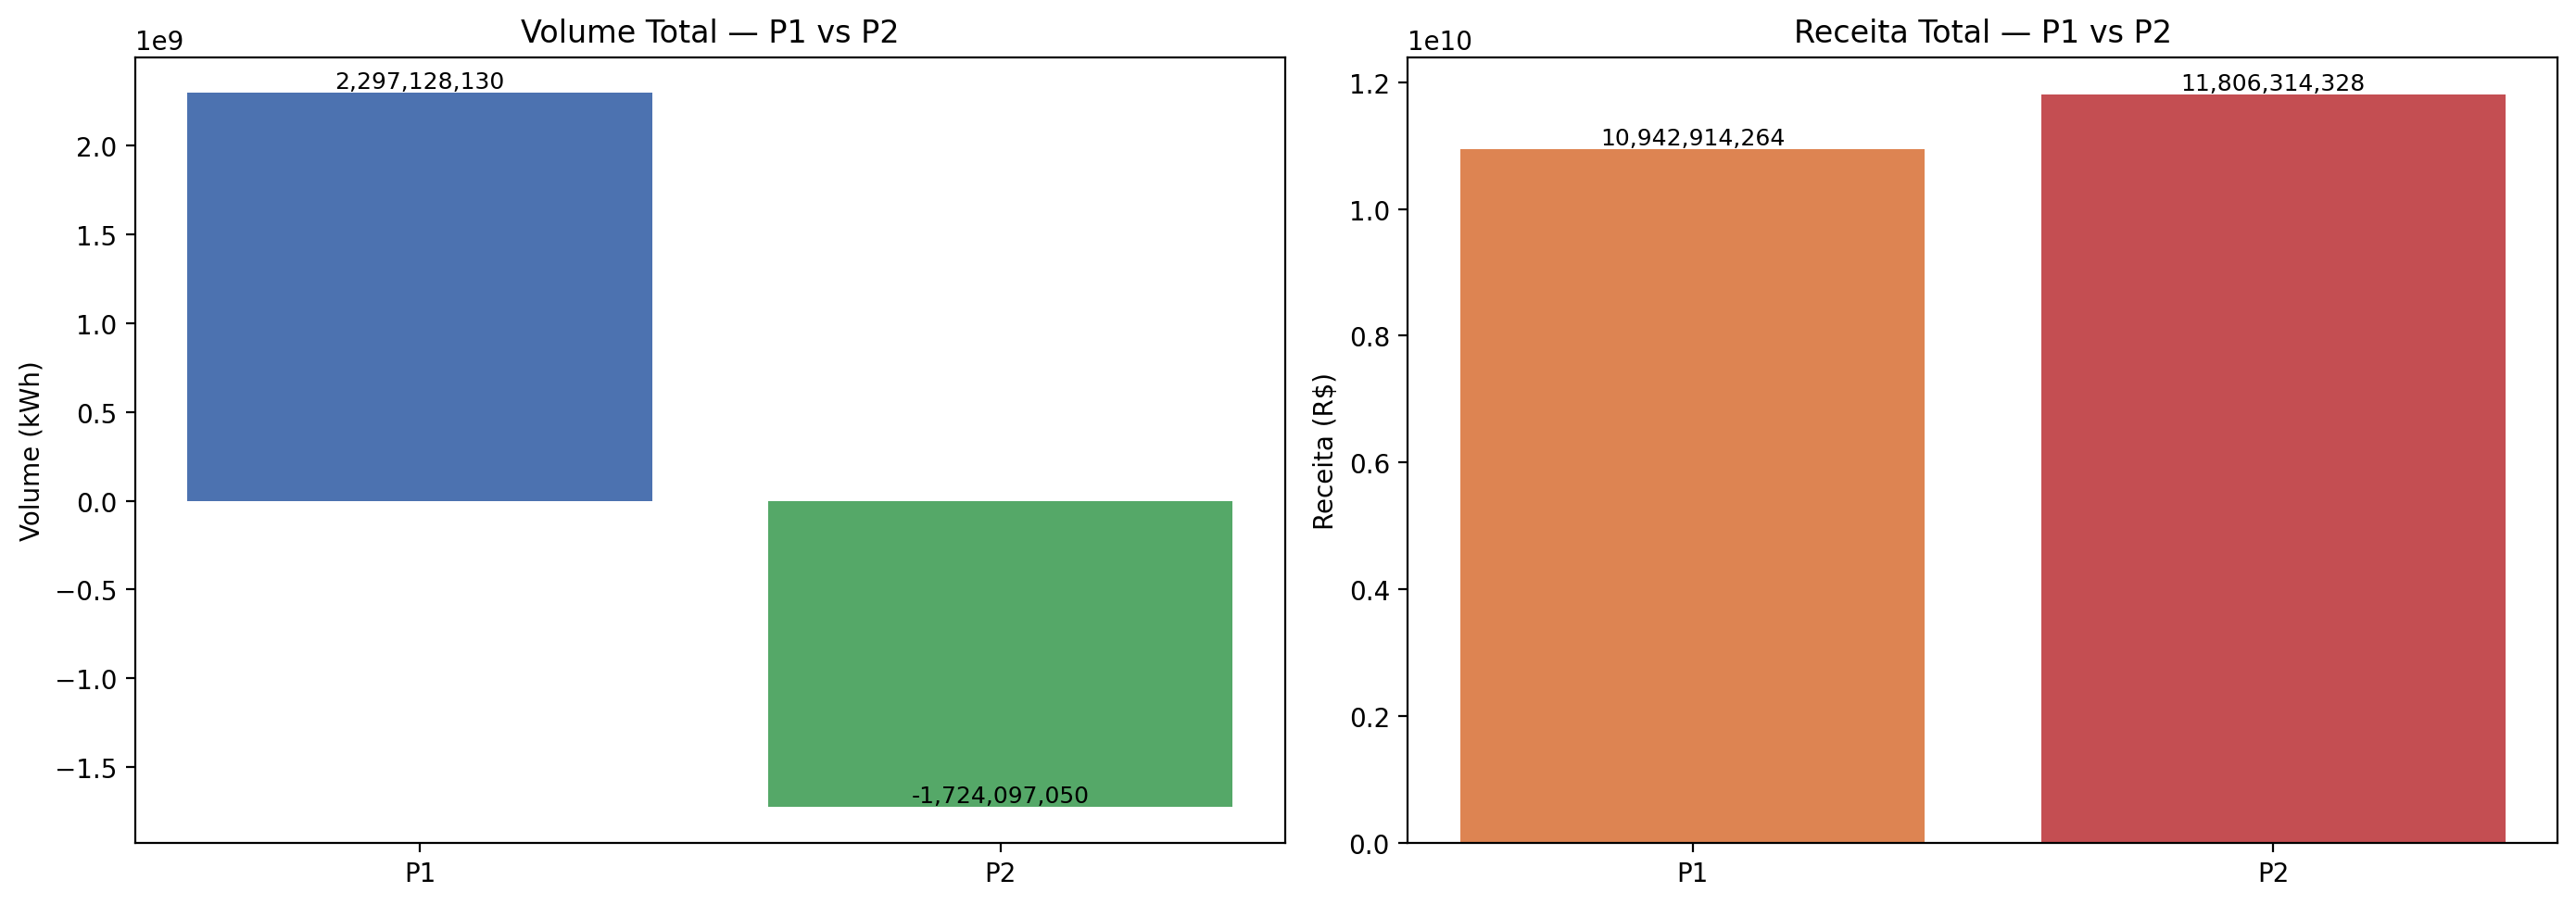

In [69]:
# Gráfico 1: dois painéis — volume (kWh) e receita (R$) separados
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Volume
x = np.arange(2)
width = 0.35
axes[0].bar(x - width/2, [vol_p1, vol_p2], width, label="P1", color="#4c72b0")
axes[0].bar(x + width/2, [vol_p1, vol_p2], width, label="P2", color="#55a868")  # wait, this is wrong
# Correção: barras lado a lado
axes[0].clear()
axes[0].bar(["P1", "P2"], [vol_p1, vol_p2], color=["#4c72b0", "#55a868"])
axes[0].set_ylabel("Volume (kWh)")
axes[0].set_title("Volume Total — P1 vs P2")
for i, v in enumerate([vol_p1, vol_p2]):
    axes[0].text(i, v, f"{v:,.0f}", ha="center", va="bottom", fontsize=9)

# Receita
axes[1].bar(["P1", "P2"], [rec_p1, rec_p2], color=["#dd8452", "#c44e52"])
axes[1].set_ylabel("Receita (R$)")
axes[1].set_title("Receita Total — P1 vs P2")
for i, v in enumerate([rec_p1, rec_p2]):
    axes[1].text(i, v, f"{v:,.0f}", ha="center", va="bottom", fontsize=9)

fig.tight_layout()
exibir_grafico(fig, "01_volume_receita_p1_p2")

Gráfico gerado: C:\VScode\v-energy-grid-360\analisys\graficos\analise_negocio\02_efeito_preco_volume_total.png


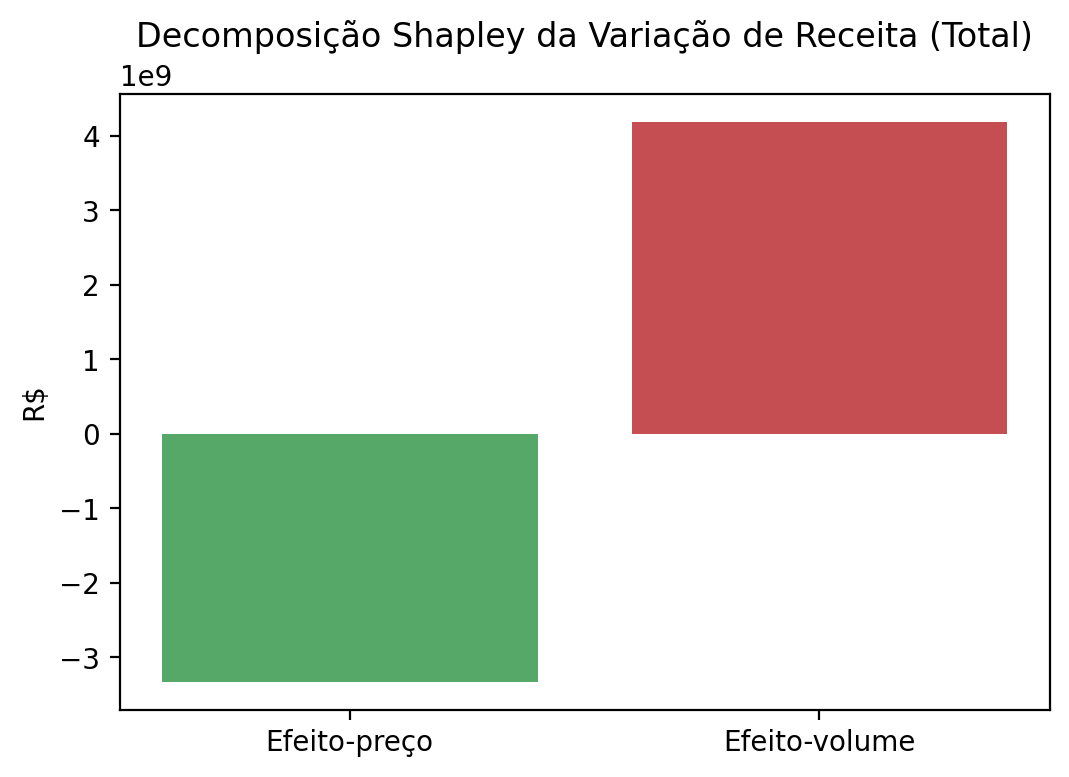

In [70]:
# Gráfico 2: efeito-preço e efeito-volume total
if efeito_preco is not None and efeito_volume is not None:
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.bar(["Efeito-preço", "Efeito-volume"], [efeito_preco, efeito_volume], color=["#55a868", "#c44e52"])
    ax.set_ylabel("R$")
    ax.set_title("Decomposição Shapley da Variação de Receita (Total)")
    exibir_grafico(fig, "02_efeito_preco_volume_total")

Gráfico gerado: C:\VScode\v-energy-grid-360\analisys\graficos\analise_negocio\03_delta_receita_por_classe.png


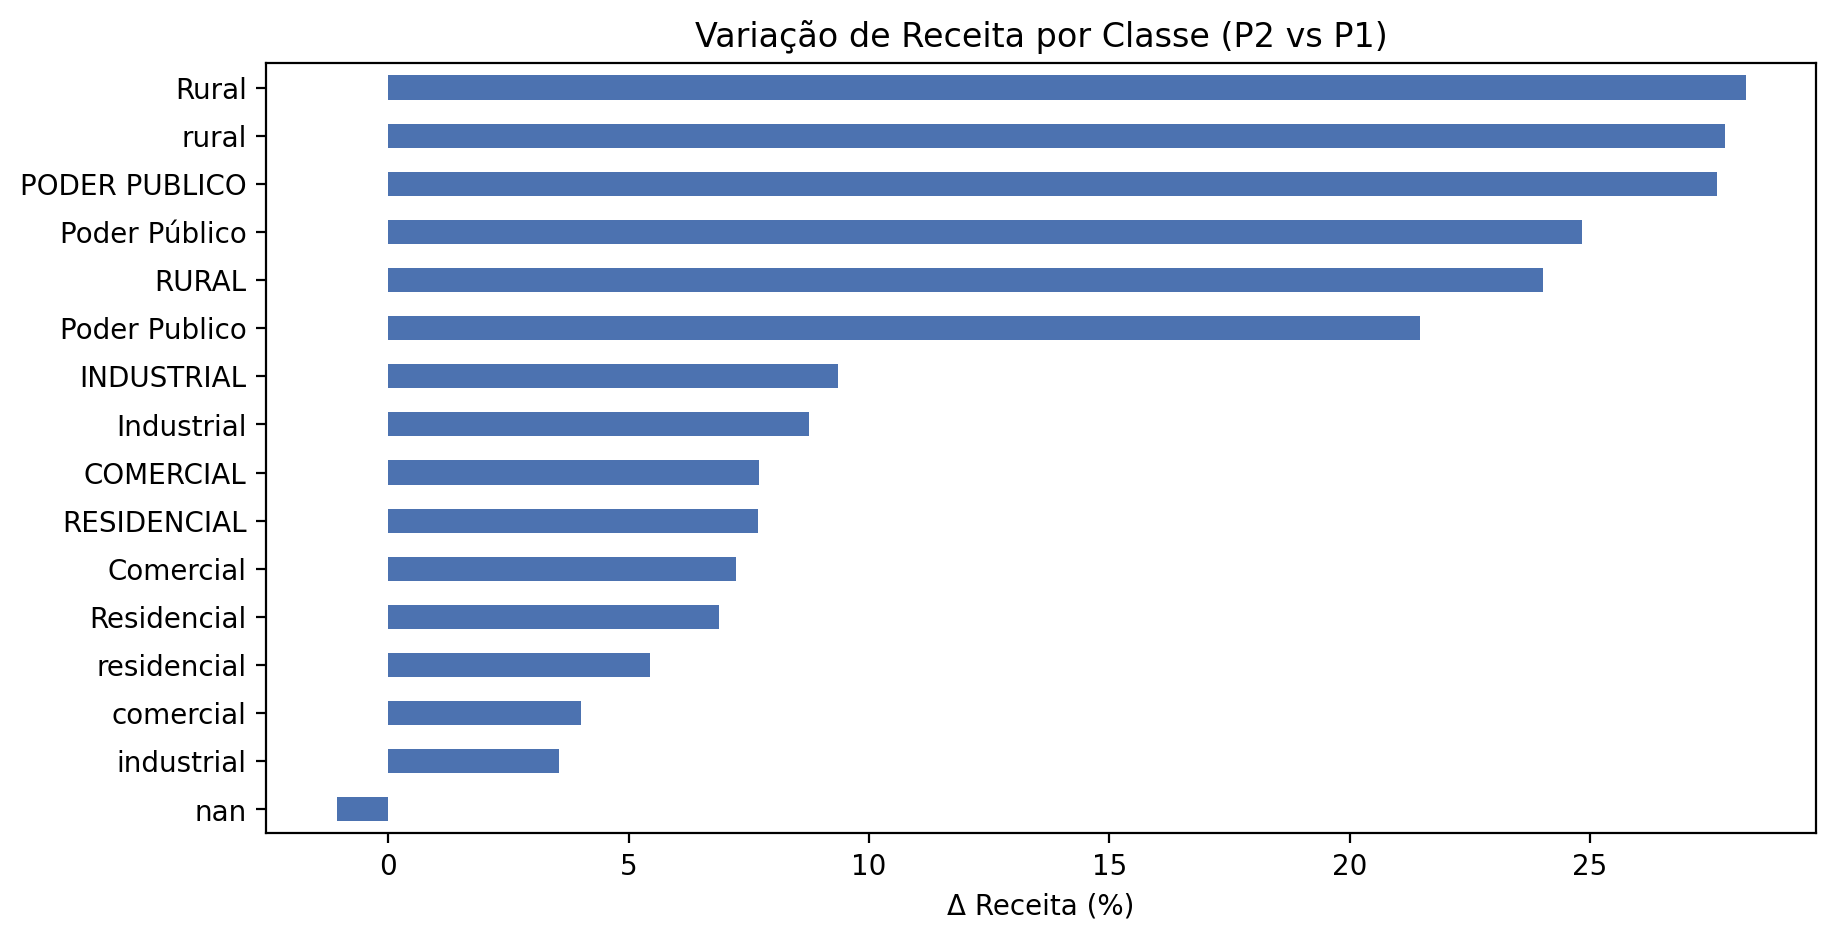

In [71]:
# Gráfico 3: Δ receita % por classe
fig, ax = plt.subplots(figsize=(10, 5))
delta_rec_classe = {g: efeitos_classe[g]["delta_rec_pct"] for g in efeitos_classe if efeitos_classe[g]["delta_rec_pct"] is not None}
pd.Series(delta_rec_classe).sort_values().plot(kind="barh", ax=ax, color="#4c72b0")
ax.set_xlabel("Δ Receita (%)")
ax.set_title("Variação de Receita por Classe (P2 vs P1)")
exibir_grafico(fig, "03_delta_receita_por_classe")

Gráfico gerado: C:\VScode\v-energy-grid-360\analisys\graficos\analise_negocio\04_delta_receita_por_municipio.png


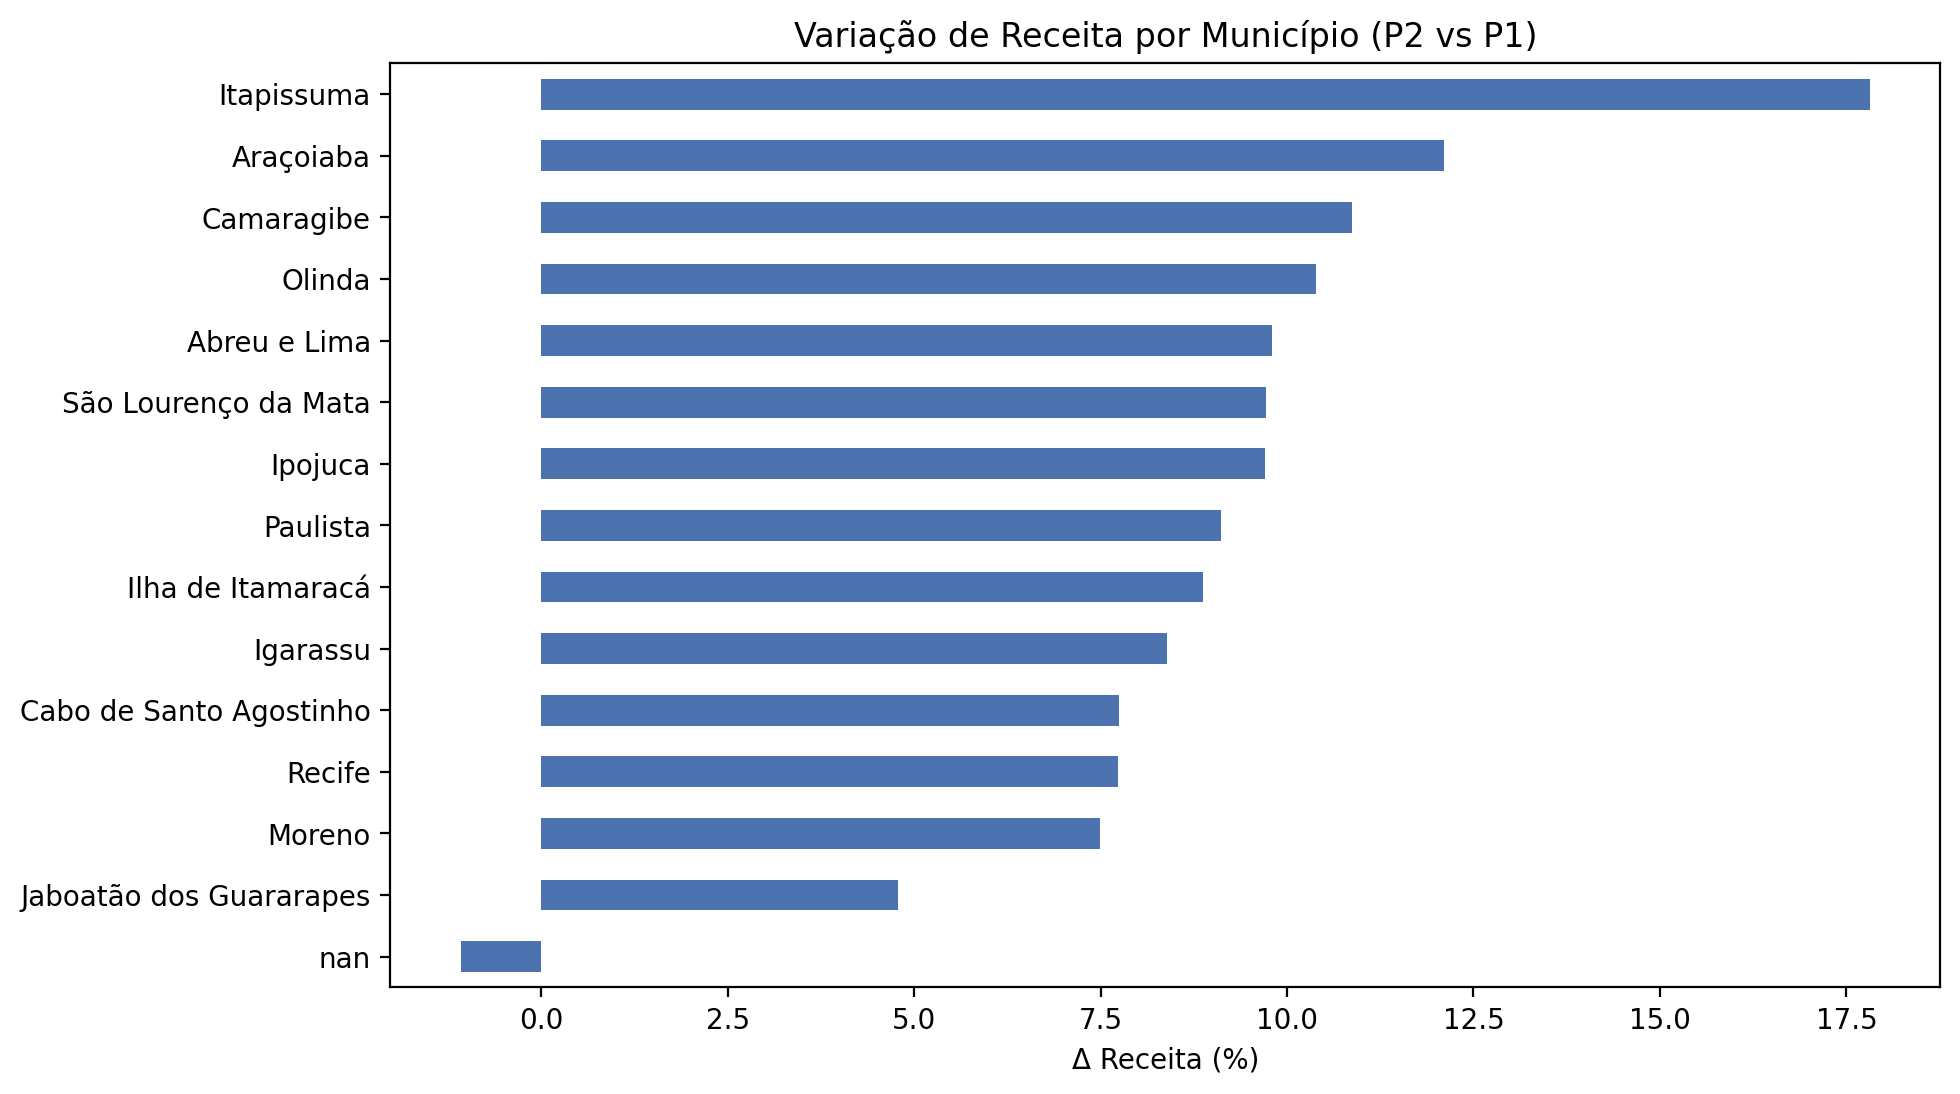

In [72]:
# Gráfico 4: Δ receita % por município
fig, ax = plt.subplots(figsize=(10, 6))
delta_rec_mun = {g: efeitos_mun[g]["delta_rec_pct"] for g in efeitos_mun if efeitos_mun[g]["delta_rec_pct"] is not None}
pd.Series(delta_rec_mun).sort_values().plot(kind="barh", ax=ax, color="#4c72b0")
ax.set_xlabel("Δ Receita (%)")
ax.set_title("Variação de Receita por Município (P2 vs P1)")
exibir_grafico(fig, "04_delta_receita_por_municipio")

Gráfico gerado: C:\VScode\v-energy-grid-360\analisys\graficos\analise_negocio\05_top_bottom_bairros_delta_receita_abs.png


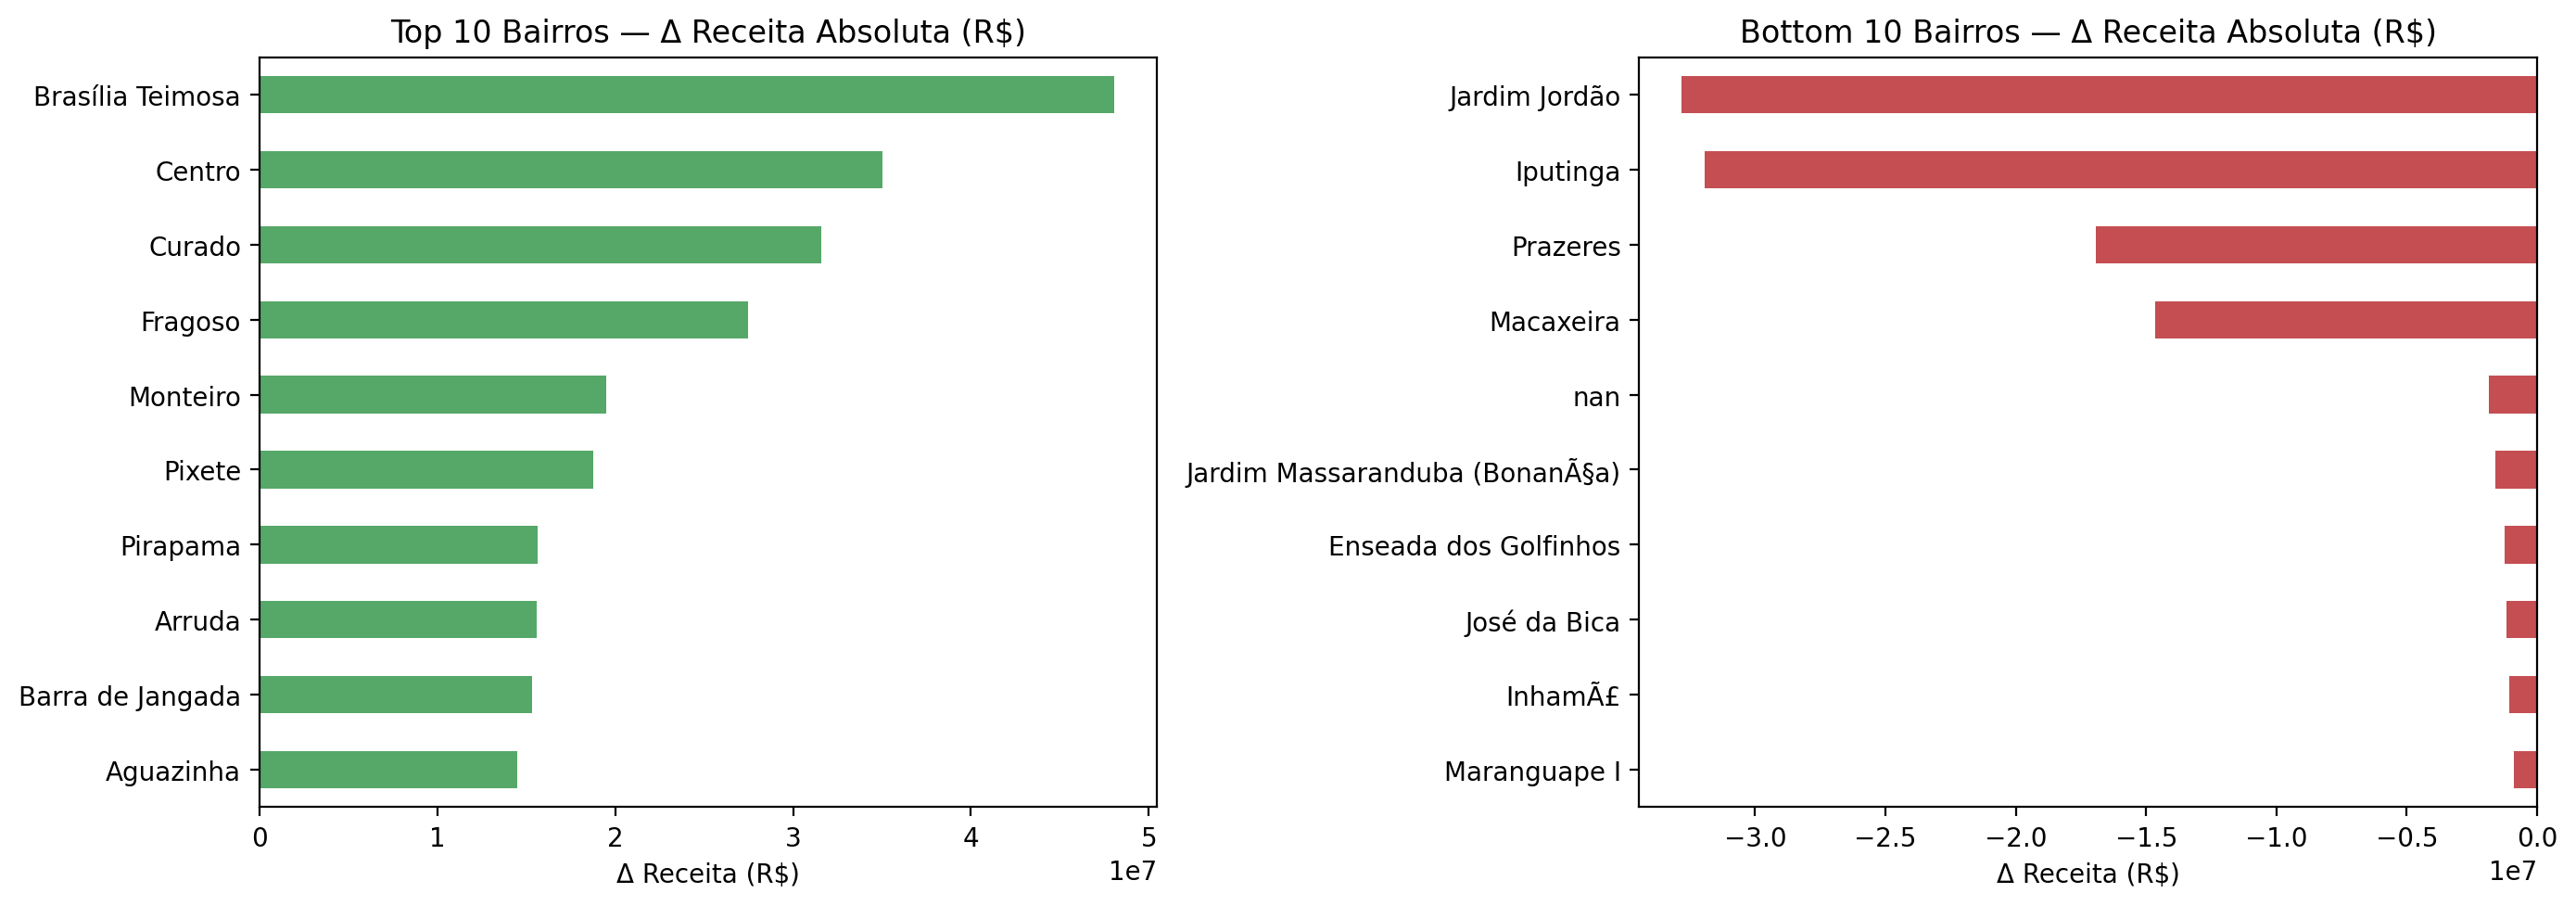

In [73]:
# Gráfico 5: top/bottom 10 bairros por Δ receita absoluto
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
pd.Series(top10_rec_abs_bai).sort_values().plot(kind="barh", ax=axes[0], color="#55a868")
axes[0].set_title("Top 10 Bairros — Δ Receita Absoluta (R$)")
axes[0].set_xlabel("Δ Receita (R$)")
pd.Series(bot10_rec_abs_bai).sort_values(ascending=False).plot(kind="barh", ax=axes[1], color="#c44e52")
axes[1].set_title("Bottom 10 Bairros — Δ Receita Absoluta (R$)")
axes[1].set_xlabel("Δ Receita (R$)")
fig.tight_layout()
exibir_grafico(fig, "05_top_bottom_bairros_delta_receita_abs")

Gráfico gerado: C:\VScode\v-energy-grid-360\analisys\graficos\analise_negocio\06_top_bottom_bairros_delta_volume_abs.png


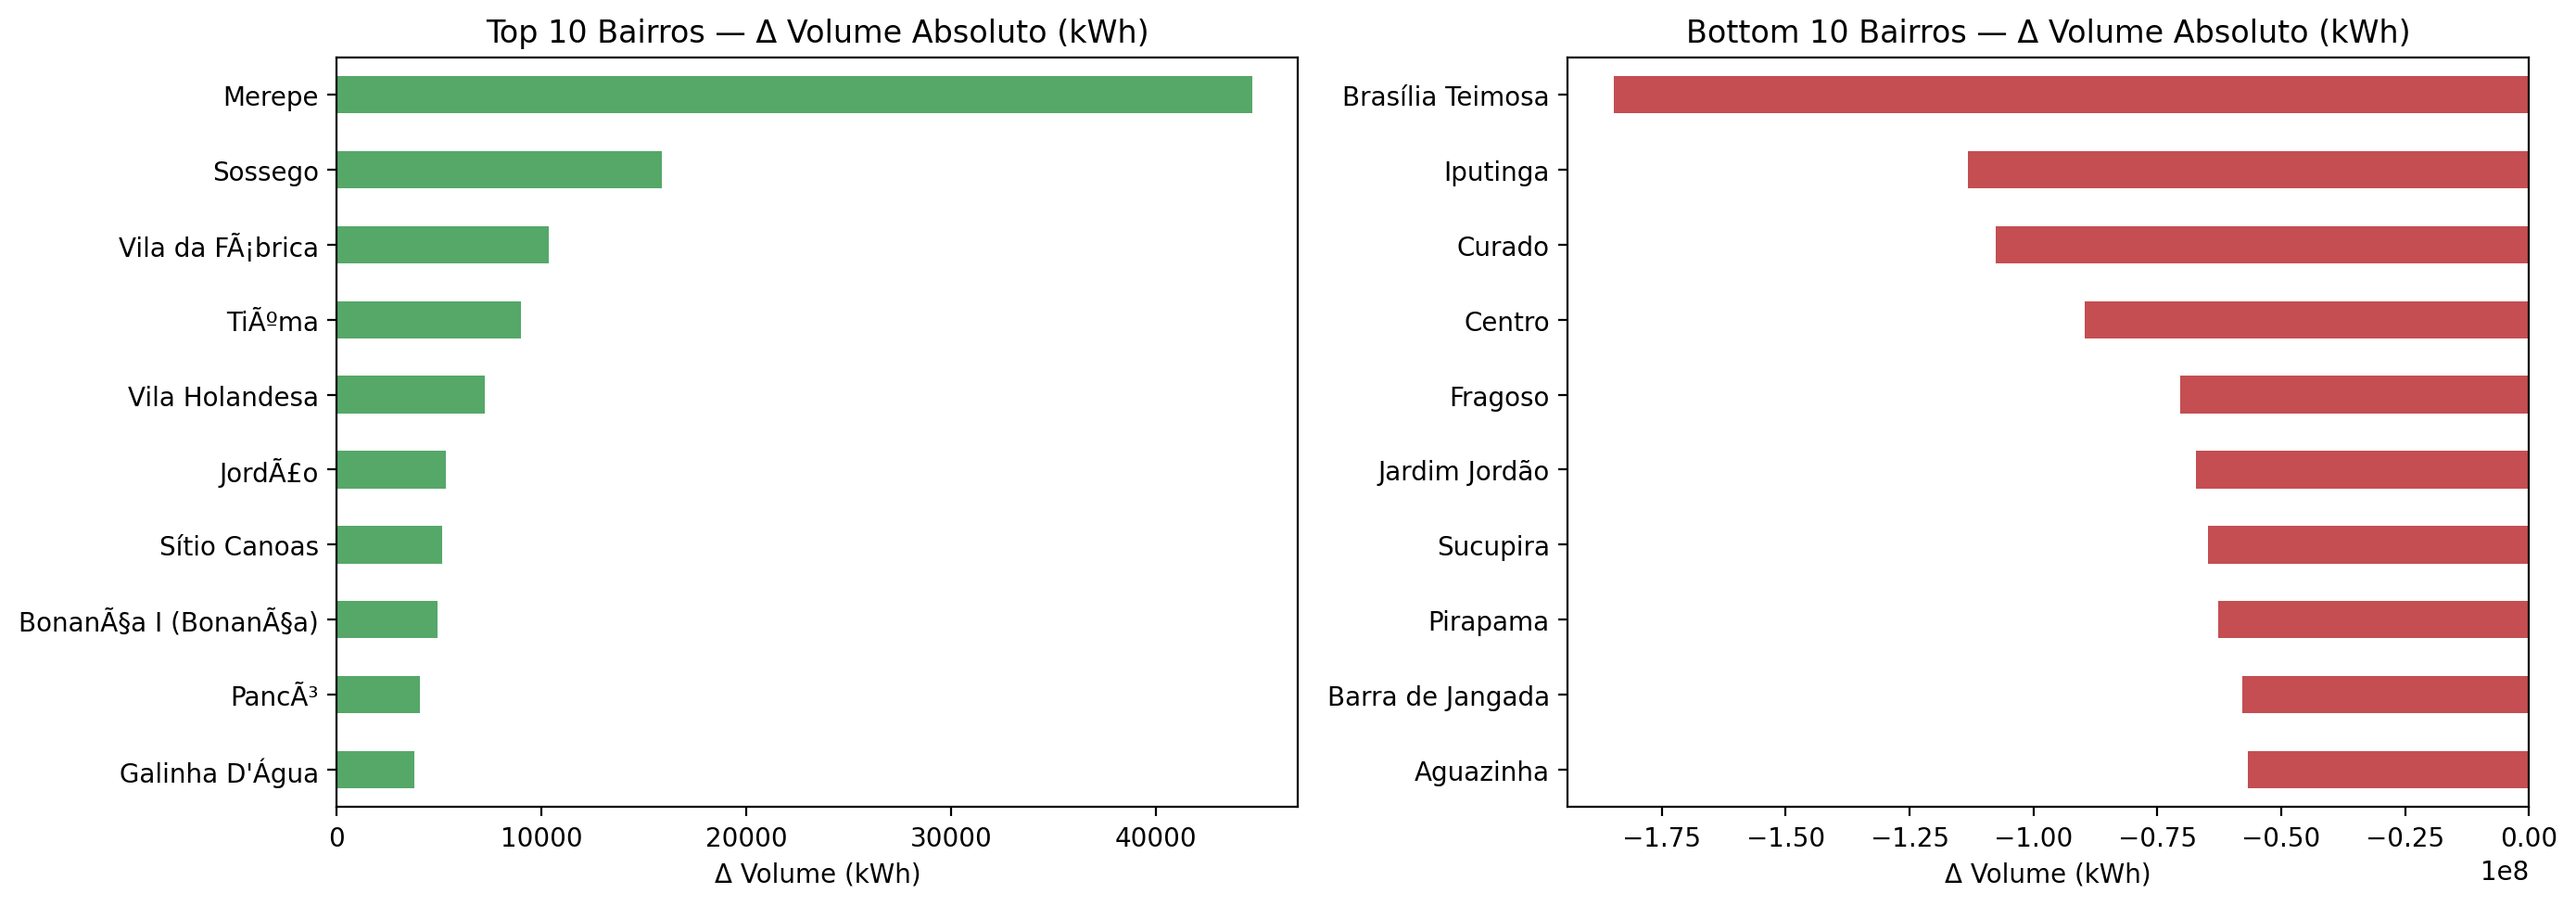

In [74]:
# Gráfico 6: top/bottom 10 bairros por Δ volume absoluto
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
pd.Series(top10_vol_abs_bai).sort_values().plot(kind="barh", ax=axes[0], color="#55a868")
axes[0].set_title("Top 10 Bairros — Δ Volume Absoluto (kWh)")
axes[0].set_xlabel("Δ Volume (kWh)")
pd.Series(bot10_vol_abs_bai).sort_values(ascending=False).plot(kind="barh", ax=axes[1], color="#c44e52")
axes[1].set_title("Bottom 10 Bairros — Δ Volume Absoluto (kWh)")
axes[1].set_xlabel("Δ Volume (kWh)")
fig.tight_layout()
exibir_grafico(fig, "06_top_bottom_bairros_delta_volume_abs")

In [75]:
# Helper para serializar JSON sem NaN/inf
def json_safe(obj):
    """Converte NaN/inf para None recursivamente e tipos numpy para Python nativo."""
    if isinstance(obj, dict):
        return {json_safe(k): json_safe(v) for k, v in obj.items()}
    elif isinstance(obj, list):
        return [json_safe(v) for v in obj]
    elif isinstance(obj, (np.integer, np.int64, np.int32)):
        return int(obj)
    elif isinstance(obj, (np.floating, np.float64, np.float32)):
        if pd.isna(obj) or np.isinf(obj):
            return None
        return float(obj)
    elif isinstance(obj, float):
        if pd.isna(obj) or np.isinf(obj):
            return None
        return obj
    elif pd.isna(obj):
        return None
    return obj

# Helper para formatar valor ou "indefinido"
def fmt_valor(v):
    if v is None or pd.isna(v) or (isinstance(v, float) and np.isinf(v)):
        return "indefinido"
    # Volume ou preço <= 0 também é "indefinido" (inclui tipos numpy)
    if isinstance(v, (int, float, np.integer, np.floating)) and float(v) <= 0:
        return "indefinido"
    return v

In [76]:
# Monta JSON de saída
resultado = {
    "periodos": {"P1": f"{P1_INI} a {P1_FIM}", "P2": f"{P2_INI} a {P2_FIM}"},
    "totais": {
        "P1": {
            "volume_kwh": fmt_valor(vol_p1),
            "receita_rs": fmt_valor(rec_p1),
            "preco_rs_kwh": fmt_valor(preco_p1),
        },
        "P2": {
            "volume_kwh": fmt_valor(vol_p2),
            "receita_rs": fmt_valor(rec_p2),
            "preco_rs_kwh": fmt_valor(preco_p2),
        },
        "delta_pct": {
            "volume": fmt_valor(delta_vol_pct),
            "receita": fmt_valor(delta_rec_pct),
            "preco": fmt_valor(delta_preco_pct),
        },
        "delta_absoluto": {
            "volume_kwh": fmt_valor(vol_p2 - vol_p1),
            "receita_rs": fmt_valor(rec_p2 - rec_p1),
        },
    },
    "efeitos_shapley_total": {
        "efeito_preco_rs": fmt_valor(efeito_preco),
        "efeito_volume_rs": fmt_valor(efeito_volume),
    },
    "consumos_positivos_negativos": {
        "P1": {"positivo_kwh": fmt_valor(pos_p1), "negativo_kwh": fmt_valor(neg_p1)},
        "P2": {"positivo_kwh": fmt_valor(pos_p2), "negativo_kwh": fmt_valor(neg_p2)},
    },
    "por_classe": {
        cl: {
            "P1": {
                "volume_kwh": fmt_valor(vol_p1_classe.get(cl, 0)),
                "receita_rs": fmt_valor(rec_p1_classe.get(cl, 0)),
                "preco_rs_kwh": fmt_valor(preco_p1_classe.get(cl)),
            },
            "P2": {
                "volume_kwh": fmt_valor(vol_p2_classe.get(cl, 0)),
                "receita_rs": fmt_valor(rec_p2_classe.get(cl, 0)),
                "preco_rs_kwh": fmt_valor(preco_p2_classe.get(cl)),
            },
            "delta_pct": {
                "volume": fmt_valor(efeitos_classe[cl]["delta_vol_pct"]),
                "receita": fmt_valor(efeitos_classe[cl]["delta_rec_pct"]),
                "preco": fmt_valor(efeitos_classe[cl]["delta_preco_pct"]),
            },
            "delta_absoluto": {
                "volume_kwh": fmt_valor(vol_delta_abs_classe.get(cl)),
                "receita_rs": fmt_valor(rec_delta_abs_classe.get(cl)),
            },
            "efeitos_shapley": {
                "efeito_preco": fmt_valor(efeitos_classe[cl]["efeito_preco"]),
                "efeito_volume": fmt_valor(efeitos_classe[cl]["efeito_volume"]),
            },
        }
        for cl in efeitos_classe
    },
    "por_municipio": {
        mun: {
            "P1": {
                "volume_kwh": fmt_valor(vol_p1_mun.get(mun, 0)),
                "receita_rs": fmt_valor(rec_p1_mun.get(mun, 0)),
                "preco_rs_kwh": fmt_valor(preco_p1_mun.get(mun)),
            },
            "P2": {
                "volume_kwh": fmt_valor(vol_p2_mun.get(mun, 0)),
                "receita_rs": fmt_valor(rec_p2_mun.get(mun, 0)),
                "preco_rs_kwh": fmt_valor(preco_p2_mun.get(mun)),
            },
            "delta_pct": {
                "volume": fmt_valor(efeitos_mun[mun]["delta_vol_pct"]),
                "receita": fmt_valor(efeitos_mun[mun]["delta_rec_pct"]),
                "preco": fmt_valor(efeitos_mun[mun]["delta_preco_pct"]),
            },
            "delta_absoluto": {
                "volume_kwh": fmt_valor(vol_delta_abs_mun.get(mun)),
                "receita_rs": fmt_valor(rec_delta_abs_mun.get(mun)),
            },
            "efeitos_shapley": {
                "efeito_preco": fmt_valor(efeitos_mun[mun]["efeito_preco"]),
                "efeito_volume": fmt_valor(efeitos_mun[mun]["efeito_volume"]),
            },
        }
        for mun in efeitos_mun
    },
    "por_bairro": {
        bai: {
            "P1": {
                "volume_kwh": fmt_valor(vol_p1_bai.get(bai, 0)),
                "receita_rs": fmt_valor(rec_p1_bai.get(bai, 0)),
                "preco_rs_kwh": fmt_valor(preco_p1_bai.get(bai)),
            },
            "P2": {
                "volume_kwh": fmt_valor(vol_p2_bai.get(bai, 0)),
                "receita_rs": fmt_valor(rec_p2_bai.get(bai, 0)),
                "preco_rs_kwh": fmt_valor(preco_p2_bai.get(bai)),
            },
            "delta_pct": {
                "volume": fmt_valor(efeitos_bai[bai]["delta_vol_pct"]),
                "receita": fmt_valor(efeitos_bai[bai]["delta_rec_pct"]),
                "preco": fmt_valor(efeitos_bai[bai]["delta_preco_pct"]),
            },
            "delta_absoluto": {
                "volume_kwh": fmt_valor(vol_delta_abs_bai.get(bai)),
                "receita_rs": fmt_valor(rec_delta_abs_bai.get(bai)),
            },
            "efeitos_shapley": {
                "efeito_preco": fmt_valor(efeitos_bai[bai]["efeito_preco"]),
                "efeito_volume": fmt_valor(efeitos_bai[bai]["efeito_volume"]),
            },
        }
        for bai in efeitos_bai
    },
    "rankings_bairro": {
        "top10_delta_receita_abs": top10_rec_abs_bai,
        "bottom10_delta_receita_abs": bot10_rec_abs_bai,
        "top10_delta_volume_abs": top10_vol_abs_bai,
        "bottom10_delta_volume_abs": bot10_vol_abs_bai,
        "top10_delta_receita_pct": top10_rec_pct_bai,
        "bottom10_delta_receita_pct": bot10_rec_pct_bai,
        "top10_delta_volume_pct": top10_vol_pct_bai,
        "bottom10_delta_volume_pct": bot10_vol_pct_bai,
    },
    "verificacoes": {
        "por_classe": json_safe(verif_classe),
        "por_municipio": json_safe(verif_mun),
        "por_bairro": json_safe(verif_bai),
    },
    "observacoes": [
        f"Falhas conversão valor_energia: {falhas_valor}",
        f"Falhas conversão consumo_kwh: {falhas_consumo}",
        f"Faturas sem UC no cadastro: {nao_casaram_fat} (não entram nos agrupamentos por classe/mun/bairro)",
        f"Leituras sem UC no cadastro: {nao_casaram_leit}",
        f"UCs duplicadas no cadastro: {n_ucs_duplicadas} UCs com {total_linhas_duplicadas} linhas extras (multiplicam no join)",
        "Soma dos grupos < total geral devido a faturas/leituras órfãs (sem cadastro) e UCs duplicadas (multiplicam linhas no join). Diferenças reportadas em 'verificacoes'.",
        "Valores 'indefinido' indicam volume/preço <= 0 ou não calculável (divisão por zero).",
        "Preço médio P1 bruto muito alto indica sujeira nos dados (ex.: consumos negativos grandes em P2).",
    ],
}

resultado = json_safe(resultado)

with open(PASTA_RESULTADOS / "henrique_receita_preco_volume_dados_brutos.json", "w", encoding="utf-8") as f:
    json.dump(resultado, f, ensure_ascii=False, indent=2, allow_nan=False)
print("JSON salvo.")

JSON salvo.
